# Header

In [1]:
setwd('/n/data1/dfci/surgonc/mittendorf/lab/chelsea/iw/github/')
source('codes/functions.R')

# library(biomaRt)
library(patchwork)
library(dplyr)

library(ggplot2)
library(grid)

options(future.globals.maxSize = 120 * 1024 * 1024 * 1024)

Loading required package: SeuratObject

Loading required package: sp

‘SeuratObject’ was built under R 4.4.0 but the current version is
4.4.2; it is recomended that you reinstall ‘SeuratObject’ as the ABI
for R may have changed


Attaching package: ‘SeuratObject’


The following objects are masked from ‘package:base’:

    intersect, t



Attaching package: ‘dplyr’


The following object is masked from ‘package:gridExtra’:

    combine


The following objects are masked from ‘package:stats’:

    filter, lag


The following objects are masked from ‘package:base’:

    intersect, setdiff, setequal, union



Attaching package: ‘anndata’


The following object is masked from ‘package:SeuratObject’:

    Layers




# Calc signature score (n=23)

## Clean data

In [25]:
dpath = 'data/09_externalds/23pt_raw'
fname = '18k_bcpt_pbmc_meta.csv'#'18k_bcpt_pbmc_meta.csv'

meta0 = read.table(glue("{dpath}/{fname}"), 
                 row.names = 1,
                 sep = ",",
                 header = TRUE)
dim(meta0)
meta0

[1] 26  5

,Accession,Title,Cell.type,Patient.diagnosis,Obesity.status
,<chr>,<chr>,<chr>,<chr>,<chr>
SRX8136156,GSM4485272,Non-Obese BC rep1,White Blood cells,breast cancer,non-obese
SRX8136157,GSM4485273,Non-Obese BC rep2,White Blood cells,breast cancer,non-obese
SRX8136158,GSM4485274,Non-Obese BC rep3,White Blood cells,breast cancer,non-obese
SRX8136159,GSM4485275,Non-Obese BC rep4,White Blood cells,breast cancer,non-obese
SRX8136160,GSM4485276,Non-Obese BC rep5,White Blood cells,breast cancer,non-obese
SRX8136161,GSM4485277,Non-Obese BC rep6,White Blood cells,breast cancer,non-obese
SRX8136162,GSM4485278,Non-Obese BC rep7,White Blood cells,breast cancer,non-obese
SRX8136163,GSM4485279,Non-Obese BC rep8,White Blood cells,breast cancer,non-obese
SRX8136164,GSM4485280,Non-Obese BC rep9,White Blood cells,breast cancer,non-obese


In [26]:
fname = 'annotation_bc_blood_samples_opensource_18k.tsv'#'18k_bcpt_pbmc_meta.csv'

meta = read.table(glue("{dpath}/{fname}"), 
                 row.names = 1,
                 sep = "\t",
                 header = TRUE)
dim(meta)
meta

[1] 32  4

,Sample,Dataset,Sample_type,GSM
,<chr>,<chr>,<chr>,<chr>
SRX8136180,SRX8136180,GSE148892,Whole_blood,GSM4485296
SRX6419103,SRX6419103,GSE133998,Whole_blood,GSM3932574
SRX8136175,SRX8136175,GSE148892,Whole_blood,GSM4485291
SRX8136165,SRX8136165,GSE148892,Whole_blood,GSM4485281
SRX8136158,SRX8136158,GSE148892,Whole_blood,GSM4485274
SRX8136162,SRX8136162,GSE148892,Whole_blood,GSM4485278
SRX8136172,SRX8136172,GSE148892,Whole_blood,GSM4485288
SRX6419098,SRX6419098,GSE133998,Whole_blood,GSM3932569
SRX9031227,SRX9031227,GSE157086,Whole_blood,GSM4752685


In [27]:
fname = 'signature_scores_bc_blood_samples_opensource_18k.tsv'

scores = read.table(glue("{dpath}/{fname}"), 
                 row.names = 1,
                 sep = "\t",
                 header = TRUE)
dim(scores)
scores

[1] 32  5

,G1_signature,G2_signature,G3_signature,G4_signature,G5_signature
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
SRX8136180,4.225651,8.5137835,2.460595,0.3224447,3.144070
SRX6419103,3.305585,6.3005437,3.968839,0.1000000,5.136247
SRX8136175,4.493297,3.9543089,5.119974,5.7171799,2.668806
SRX8136165,7.158963,3.2155109,4.872542,1.0076999,3.810841
SRX8136158,6.437120,5.5186563,4.352223,0.7701919,2.129005
SRX8136162,2.723668,5.2529535,4.100817,2.9339280,5.688330
SRX8136172,5.573812,5.9754598,4.246434,2.0567109,2.888763
SRX6419098,3.426877,4.2559238,4.758429,1.5366878,6.599685
SRX9031227,2.469484,0.4196402,6.741274,3.9331460,10.000000


In [28]:
scores2 <- scores[rownames(meta), , drop = FALSE]

# Merge by column (the rownames will now match meta's order)
meta2 <- cbind(meta, scores2)

meta2

,Sample,Dataset,Sample_type,GSM,G1_signature,G2_signature,G3_signature,G4_signature,G5_signature
,<chr>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
SRX8136180,SRX8136180,GSE148892,Whole_blood,GSM4485296,4.225651,8.5137835,2.460595,0.3224447,3.144070
SRX6419103,SRX6419103,GSE133998,Whole_blood,GSM3932574,3.305585,6.3005437,3.968839,0.1000000,5.136247
SRX8136175,SRX8136175,GSE148892,Whole_blood,GSM4485291,4.493297,3.9543089,5.119974,5.7171799,2.668806
SRX8136165,SRX8136165,GSE148892,Whole_blood,GSM4485281,7.158963,3.2155109,4.872542,1.0076999,3.810841
SRX8136158,SRX8136158,GSE148892,Whole_blood,GSM4485274,6.437120,5.5186563,4.352223,0.7701919,2.129005
SRX8136162,SRX8136162,GSE148892,Whole_blood,GSM4485278,2.723668,5.2529535,4.100817,2.9339280,5.688330
SRX8136172,SRX8136172,GSE148892,Whole_blood,GSM4485288,5.573812,5.9754598,4.246434,2.0567109,2.888763
SRX6419098,SRX6419098,GSE133998,Whole_blood,GSM3932569,3.426877,4.2559238,4.758429,1.5366878,6.599685
SRX9031227,SRX9031227,GSE157086,Whole_blood,GSM4752685,2.469484,0.4196402,6.741274,3.9331460,10.000000


In [29]:
fname = 'GSE148892_norm_counts_TPM_GRCh38.p13_NCBI_aka18k.tsv'

dat = read.table(glue("{dpath}/{fname}"), 
                 row.names = 1,
                 sep = "\t",
                 header = TRUE)

# dat = t(dat)
# dat = dat[,rownames(meta2)]
dat

,GSM4485272,GSM4485273,GSM4485274,GSM4485275,GSM4485276,GSM4485277,GSM4485278,GSM4485279,GSM4485280,GSM4485281,⋯,GSM4485288,GSM4485289,GSM4485290,GSM4485291,GSM4485292,GSM4485293,GSM4485294,GSM4485295,GSM4485296,GSM4485297
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
100287102,0.44070,1.6860,6.254e-01,2.928e+00,1.609e+00,1.665e+00,2.884e+00,0.85950,2.503e+00,2.51100,⋯,2.010e+00,0.82960,1.721e+00,1.572e+00,0.60880,1.5530,0.33890,0.44870,1.406e+00,1.1240
653635,7.78800,29.9100,1.382e+01,1.930e+01,2.683e+01,1.423e+01,1.484e+01,10.82000,2.607e+01,10.86000,⋯,1.126e+01,8.55500,2.325e+01,2.073e+01,15.73000,22.2600,8.04700,13.90000,1.904e+01,21.5700
102466751,11.53000,58.0200,1.266e+01,3.766e+01,2.791e+01,3.236e+01,1.784e+01,18.38000,1.871e+01,12.20000,⋯,1.989e+01,13.44000,2.951e+01,3.502e+01,24.65000,48.8200,12.94000,21.80000,2.562e+01,15.1700
107985730,0.00000,0.4314,0.000e+00,0.000e+00,3.528e-01,0.000e+00,0.000e+00,0.00000,0.000e+00,0.00000,⋯,0.000e+00,0.00000,0.000e+00,0.000e+00,0.00000,0.0000,0.00000,0.00000,0.000e+00,0.0000
100302278,0.00000,0.0000,0.000e+00,0.000e+00,0.000e+00,0.000e+00,0.000e+00,0.00000,0.000e+00,0.00000,⋯,0.000e+00,0.00000,0.000e+00,0.000e+00,0.00000,0.0000,0.00000,0.00000,0.000e+00,1.4950
645520,0.04956,0.0000,0.000e+00,0.000e+00,0.000e+00,0.000e+00,0.000e+00,0.00000,0.000e+00,0.00000,⋯,1.088e-01,0.00000,1.480e-01,3.831e-02,0.00000,0.0000,0.00000,0.00000,0.000e+00,0.0000
79501,0.00000,0.0000,0.000e+00,3.099e-01,0.000e+00,0.000e+00,0.000e+00,0.00000,0.000e+00,0.00000,⋯,0.000e+00,0.00000,0.000e+00,0.000e+00,0.00000,0.0000,0.00000,0.00000,0.000e+00,0.0000
100996442,1.09900,6.9710,7.037e-01,1.337e+00,3.685e+00,2.107e+00,2.496e+00,1.70600,4.159e+00,2.12500,⋯,3.995e+00,0.84010,5.535e+00,1.672e+00,2.19200,6.6910,2.33700,4.14000,3.109e+00,3.7090
729737,29.84000,154.2000,2.013e+01,4.205e+01,7.417e+01,3.012e+01,9.510e+01,36.81000,5.648e+01,60.30000,⋯,4.291e+01,19.41000,6.912e+01,4.196e+01,35.99000,102.4000,41.02000,84.95000,7.926e+01,30.2200


In [30]:
fname = 'Human.GRCh38.p13.annot.tsv'

anno_genes = read.table(glue("{dpath}/{fname}"), 
                 row.names = 1,
                 sep = "\t",
                 header = TRUE)

# dat = t(dat)
# dat = dat[,rownames(meta2)]
anno_genes

,Symbol
,<chr>
100287102,DDX11L1
653635,WASH7P
102466751,MIR6859-1
107985730,MIR1302-2HG
100302278,MIR1302-2
645520,FAM138A
79501,OR4F5
100996442,LOC100996442
729737,LOC729737


In [31]:
anno_genes2 <- anno_genes[rownames(dat), , drop = FALSE]

# Merge by column (the rownames will now match meta's order)
dat2 <- cbind(anno_genes2, dat)

rownames(dat2) = dat2$SYMBOL
dat2

Symbol,GSM4485272,GSM4485273,GSM4485274,GSM4485275,GSM4485276,GSM4485277,GSM4485278,GSM4485279,GSM4485280,⋯,GSM4485288,GSM4485289,GSM4485290,GSM4485291,GSM4485292,GSM4485293,GSM4485294,GSM4485295,GSM4485296,GSM4485297
<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
DDX11L1,0.44070,1.6860,6.254e-01,2.928e+00,1.609e+00,1.665e+00,2.884e+00,0.85950,2.503e+00,⋯,2.010e+00,0.82960,1.721e+00,1.572e+00,0.60880,1.5530,0.33890,0.44870,1.406e+00,1.1240
WASH7P,7.78800,29.9100,1.382e+01,1.930e+01,2.683e+01,1.423e+01,1.484e+01,10.82000,2.607e+01,⋯,1.126e+01,8.55500,2.325e+01,2.073e+01,15.73000,22.2600,8.04700,13.90000,1.904e+01,21.5700
MIR6859-1,11.53000,58.0200,1.266e+01,3.766e+01,2.791e+01,3.236e+01,1.784e+01,18.38000,1.871e+01,⋯,1.989e+01,13.44000,2.951e+01,3.502e+01,24.65000,48.8200,12.94000,21.80000,2.562e+01,15.1700
MIR1302-2HG,0.00000,0.4314,0.000e+00,0.000e+00,3.528e-01,0.000e+00,0.000e+00,0.00000,0.000e+00,⋯,0.000e+00,0.00000,0.000e+00,0.000e+00,0.00000,0.0000,0.00000,0.00000,0.000e+00,0.0000
MIR1302-2,0.00000,0.0000,0.000e+00,0.000e+00,0.000e+00,0.000e+00,0.000e+00,0.00000,0.000e+00,⋯,0.000e+00,0.00000,0.000e+00,0.000e+00,0.00000,0.0000,0.00000,0.00000,0.000e+00,1.4950
FAM138A,0.04956,0.0000,0.000e+00,0.000e+00,0.000e+00,0.000e+00,0.000e+00,0.00000,0.000e+00,⋯,1.088e-01,0.00000,1.480e-01,3.831e-02,0.00000,0.0000,0.00000,0.00000,0.000e+00,0.0000
OR4F5,0.00000,0.0000,0.000e+00,3.099e-01,0.000e+00,0.000e+00,0.000e+00,0.00000,0.000e+00,⋯,0.000e+00,0.00000,0.000e+00,0.000e+00,0.00000,0.0000,0.00000,0.00000,0.000e+00,0.0000
LOC100996442,1.09900,6.9710,7.037e-01,1.337e+00,3.685e+00,2.107e+00,2.496e+00,1.70600,4.159e+00,⋯,3.995e+00,0.84010,5.535e+00,1.672e+00,2.19200,6.6910,2.33700,4.14000,3.109e+00,3.7090
LOC729737,29.84000,154.2000,2.013e+01,4.205e+01,7.417e+01,3.012e+01,9.510e+01,36.81000,5.648e+01,⋯,4.291e+01,19.41000,6.912e+01,4.196e+01,35.99000,102.4000,41.02000,84.95000,7.926e+01,30.2200


In [32]:
fname = 'gse201025_srx_gsm.csv'

srx = read.table(glue("{dpath}/{fname}"), 
                 row.names = 1,
                 sep = ",",
                 header = TRUE)


srx

,gsm,srx
,<chr>,<chr>
4571_MA_01,GSM6050381,SRX14923865
4571_MA_02,GSM6050382,SRX14923866
4571_MA_03,GSM6050383,SRX14923867
4571_MA_04,GSM6050384,SRX14923868
4571_MA_05,GSM6050385,SRX14923869
4571_MA_06,GSM6050386,SRX14923870
4571_MA_07,GSM6050387,SRX14923871
4571_MA_08,GSM6050388,SRX14923872
4571_MA_09,GSM6050389,SRX14923873


In [33]:
fname = '18k_srx_gsm.csv'

srx = read.table(glue("{dpath}/{fname}"), 
                 row.names = 1,
                 sep = ",",
                 header = TRUE)


srx

,Sample.Name
,<chr>
SRX8136156,GSM4485272
SRX8136157,GSM4485273
SRX8136158,GSM4485274
SRX8136159,GSM4485275
SRX8136160,GSM4485276
SRX8136161,GSM4485277
SRX8136162,GSM4485278
SRX8136163,GSM4485279
SRX8136164,GSM4485280


In [34]:
# Assume dat2 is your data frame (columns: GSM IDs), and srx is your mapping (rownames: SRX, value: GSM)

# 1. Get current column names of dat2 (excluding the first column if it's "Symbol")
gsm_cols <- colnames(dat2)
if ("Symbol" %in% gsm_cols) {
  gsm_cols <- gsm_cols[gsm_cols != "Symbol"]
}

# 2. Create a named vector for mapping GSM → SRX
gsm_to_srx <- setNames(rownames(srx), srx[[1]])  # names: GSM, values: SRX

# 3. Replace column names using the mapping
new_colnames <- colnames(dat2)
for (i in seq_along(new_colnames)) {
  if (new_colnames[i] %in% names(gsm_to_srx)) {
    new_colnames[i] <- gsm_to_srx[[new_colnames[i]]]
  }
}
colnames(dat2) <- new_colnames

# 4. Check result
rownames(dat2) <- make.unique(as.character(dat2$Symbol))
dat2$Symbol <- NULL   # Remove Symbol column if you don't need it

dat2

,SRX8136156,SRX8136157,SRX8136158,SRX8136159,SRX8136160,SRX8136161,SRX8136162,SRX8136163,SRX8136164,SRX8136165,⋯,SRX8136172,SRX8136173,SRX8136174,SRX8136175,SRX8136176,SRX8136177,SRX8136178,SRX8136179,SRX8136180,SRX8136181
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
DDX11L1,0.44070,1.6860,6.254e-01,2.928e+00,1.609e+00,1.665e+00,2.884e+00,0.85950,2.503e+00,2.51100,⋯,2.010e+00,0.82960,1.721e+00,1.572e+00,0.60880,1.5530,0.33890,0.44870,1.406e+00,1.1240
WASH7P,7.78800,29.9100,1.382e+01,1.930e+01,2.683e+01,1.423e+01,1.484e+01,10.82000,2.607e+01,10.86000,⋯,1.126e+01,8.55500,2.325e+01,2.073e+01,15.73000,22.2600,8.04700,13.90000,1.904e+01,21.5700
MIR6859-1,11.53000,58.0200,1.266e+01,3.766e+01,2.791e+01,3.236e+01,1.784e+01,18.38000,1.871e+01,12.20000,⋯,1.989e+01,13.44000,2.951e+01,3.502e+01,24.65000,48.8200,12.94000,21.80000,2.562e+01,15.1700
MIR1302-2HG,0.00000,0.4314,0.000e+00,0.000e+00,3.528e-01,0.000e+00,0.000e+00,0.00000,0.000e+00,0.00000,⋯,0.000e+00,0.00000,0.000e+00,0.000e+00,0.00000,0.0000,0.00000,0.00000,0.000e+00,0.0000
MIR1302-2,0.00000,0.0000,0.000e+00,0.000e+00,0.000e+00,0.000e+00,0.000e+00,0.00000,0.000e+00,0.00000,⋯,0.000e+00,0.00000,0.000e+00,0.000e+00,0.00000,0.0000,0.00000,0.00000,0.000e+00,1.4950
FAM138A,0.04956,0.0000,0.000e+00,0.000e+00,0.000e+00,0.000e+00,0.000e+00,0.00000,0.000e+00,0.00000,⋯,1.088e-01,0.00000,1.480e-01,3.831e-02,0.00000,0.0000,0.00000,0.00000,0.000e+00,0.0000
OR4F5,0.00000,0.0000,0.000e+00,3.099e-01,0.000e+00,0.000e+00,0.000e+00,0.00000,0.000e+00,0.00000,⋯,0.000e+00,0.00000,0.000e+00,0.000e+00,0.00000,0.0000,0.00000,0.00000,0.000e+00,0.0000
LOC100996442,1.09900,6.9710,7.037e-01,1.337e+00,3.685e+00,2.107e+00,2.496e+00,1.70600,4.159e+00,2.12500,⋯,3.995e+00,0.84010,5.535e+00,1.672e+00,2.19200,6.6910,2.33700,4.14000,3.109e+00,3.7090
LOC729737,29.84000,154.2000,2.013e+01,4.205e+01,7.417e+01,3.012e+01,9.510e+01,36.81000,5.648e+01,60.30000,⋯,4.291e+01,19.41000,6.912e+01,4.196e+01,35.99000,102.4000,41.02000,84.95000,7.926e+01,30.2200


In [35]:
common_ids <- intersect(colnames(dat2), rownames(meta2))
meta3 <- meta2[common_ids, , drop = FALSE]

meta3

,Sample,Dataset,Sample_type,GSM,G1_signature,G2_signature,G3_signature,G4_signature,G5_signature
,<chr>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
SRX8136156,SRX8136156,GSE148892,Whole_blood,GSM4485272,3.915864,3.443940,6.474928,0.6627942,7.487532
SRX8136157,SRX8136157,GSE148892,Whole_blood,GSM4485273,3.998675,6.074275,5.193996,0.5832359,4.060746
SRX8136158,SRX8136158,GSE148892,Whole_blood,GSM4485274,6.437120,5.518656,4.352223,0.7701919,2.129005
SRX8136160,SRX8136160,GSE148892,Whole_blood,GSM4485276,6.628620,2.361768,5.658363,2.9828247,3.310755
SRX8136161,SRX8136161,GSE148892,Whole_blood,GSM4485277,6.799967,1.674307,5.666059,4.0981414,3.022511
SRX8136162,SRX8136162,GSE148892,Whole_blood,GSM4485278,2.723668,5.252953,4.100817,2.9339280,5.688330
SRX8136163,SRX8136163,GSE148892,Whole_blood,GSM4485279,1.874542,5.366436,6.559609,5.1914584,2.409984
SRX8136165,SRX8136165,GSE148892,Whole_blood,GSM4485281,7.158963,3.215511,4.872542,1.0076999,3.810841
SRX8136167,SRX8136167,GSE148892,Whole_blood,GSM4485283,2.959670,5.746122,5.848580,4.7556670,2.378611


In [36]:
dat3 <- dat2[, common_ids, drop = FALSE]

dat3

,SRX8136156,SRX8136157,SRX8136158,SRX8136160,SRX8136161,SRX8136162,SRX8136163,SRX8136165,SRX8136167,SRX8136168,⋯,SRX8136172,SRX8136173,SRX8136174,SRX8136175,SRX8136176,SRX8136177,SRX8136178,SRX8136179,SRX8136180,SRX8136181
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
DDX11L1,0.44070,1.6860,6.254e-01,1.609e+00,1.665e+00,2.884e+00,0.85950,2.51100,6.729e-01,1.02500,⋯,2.010e+00,0.82960,1.721e+00,1.572e+00,0.60880,1.5530,0.33890,0.44870,1.406e+00,1.1240
WASH7P,7.78800,29.9100,1.382e+01,2.683e+01,1.423e+01,1.484e+01,10.82000,10.86000,2.629e+01,6.07700,⋯,1.126e+01,8.55500,2.325e+01,2.073e+01,15.73000,22.2600,8.04700,13.90000,1.904e+01,21.5700
MIR6859-1,11.53000,58.0200,1.266e+01,2.791e+01,3.236e+01,1.784e+01,18.38000,12.20000,2.997e+01,5.41400,⋯,1.989e+01,13.44000,2.951e+01,3.502e+01,24.65000,48.8200,12.94000,21.80000,2.562e+01,15.1700
MIR1302-2HG,0.00000,0.4314,0.000e+00,3.528e-01,0.000e+00,0.000e+00,0.00000,0.00000,0.000e+00,0.00000,⋯,0.000e+00,0.00000,0.000e+00,0.000e+00,0.00000,0.0000,0.00000,0.00000,0.000e+00,0.0000
MIR1302-2,0.00000,0.0000,0.000e+00,0.000e+00,0.000e+00,0.000e+00,0.00000,0.00000,0.000e+00,0.00000,⋯,0.000e+00,0.00000,0.000e+00,0.000e+00,0.00000,0.0000,0.00000,0.00000,0.000e+00,1.4950
FAM138A,0.04956,0.0000,0.000e+00,0.000e+00,0.000e+00,0.000e+00,0.00000,0.00000,0.000e+00,0.00000,⋯,1.088e-01,0.00000,1.480e-01,3.831e-02,0.00000,0.0000,0.00000,0.00000,0.000e+00,0.0000
OR4F5,0.00000,0.0000,0.000e+00,0.000e+00,0.000e+00,0.000e+00,0.00000,0.00000,0.000e+00,0.00000,⋯,0.000e+00,0.00000,0.000e+00,0.000e+00,0.00000,0.0000,0.00000,0.00000,0.000e+00,0.0000
LOC100996442,1.09900,6.9710,7.037e-01,3.685e+00,2.107e+00,2.496e+00,1.70600,2.12500,3.218e+00,0.61690,⋯,3.995e+00,0.84010,5.535e+00,1.672e+00,2.19200,6.6910,2.33700,4.14000,3.109e+00,3.7090
LOC729737,29.84000,154.2000,2.013e+01,7.417e+01,3.012e+01,9.510e+01,36.81000,60.30000,6.397e+01,16.55000,⋯,4.291e+01,19.41000,6.912e+01,4.196e+01,35.99000,102.4000,41.02000,84.95000,7.926e+01,30.2200


In [37]:
write.csv(dat3, 'data/09_externalds/23pt_clean/clean_expr.csv')

In [38]:
write.csv(meta3, 'data/09_externalds/23pt_clean/clean_meta.csv')

Run this in R console - this jupyter with R kernel is weird b/c kernel dies when library(GSVA)

module load gcc/14.2.0 R/4.4.2
R
```R
library(GSVA)
library(GSEABase)
#--------------- load geneset 
gmt_file <- "data/08_signature/NHB_up.gmt" #"data/geneset/NHB_dn.gmt"
gsets <- getGmt(gmt_file)

#--------------- load meta and dat
meta3 = read.csv('data/09_externalds/23pt_clean/clean_meta.csv', row.names=1)
dat3 = read.csv('data/09_externalds/23pt_clean/clean_expr.csv', row.names=1)

pheno_data <- AnnotatedDataFrame(data = meta3)
eset <- ExpressionSet(
  assayData = as.matrix(dat3),  # Expression data matrix
  phenoData = pheno_data                   # Phenotype data
)

experimentData(eset) <- MIAME(
  name = "ex23",
)

#--------------- calc ssgsea
ssgsea = ssgseaParam(eset, gsets)

ssgsea_out = gsva(ssgsea)
ssgsea_out_t = t(exprs(ssgsea_out))


#--------------- merge ssgsea output and meta data
mg <- merge(meta3, ssgsea_out_t, by = "row.names")
rownames(mg) <- mg$Row.names
mg$Row.names <- NULL

write.csv(mg, 'data/09_externalds/23pt_clean/gsva_23pt_NhbBcSigUp.csv') # write.csv(mg, 'data/09_externalds/23pt_clean/gsva_23pt_NhbBcSigDn.csv')

```

## Up genes

In [2]:
mg = read.csv('data/09_externalds/23pt_clean/gsva_23pt_NhbBcSigUp.csv', 
              row.name=1)
mg

,Sample,Dataset,Sample_type,GSM,G1_signature,G2_signature,G3_signature,G4_signature,G5_signature,NHB.BC.Up.All,NHB.BC.Up.Protein
,<chr>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
SRX8136156,SRX8136156,GSE148892,Whole_blood,GSM4485272,3.915864,3.443940,6.474928,0.6627942,7.487532,3.343087,3.685565
SRX8136157,SRX8136157,GSE148892,Whole_blood,GSM4485273,3.998675,6.074275,5.193996,0.5832359,4.060746,3.035975,3.474618
SRX8136158,SRX8136158,GSE148892,Whole_blood,GSM4485274,6.437120,5.518656,4.352223,0.7701919,2.129005,3.021615,3.494688
SRX8136160,SRX8136160,GSE148892,Whole_blood,GSM4485276,6.628620,2.361768,5.658363,2.9828247,3.310755,3.026681,3.546014
SRX8136161,SRX8136161,GSE148892,Whole_blood,GSM4485277,6.799967,1.674307,5.666059,4.0981414,3.022511,3.034603,3.695045
SRX8136162,SRX8136162,GSE148892,Whole_blood,GSM4485278,2.723668,5.252953,4.100817,2.9339280,5.688330,3.343556,3.723555
SRX8136163,SRX8136163,GSE148892,Whole_blood,GSM4485279,1.874542,5.366436,6.559609,5.1914584,2.409984,2.994769,3.479058
SRX8136165,SRX8136165,GSE148892,Whole_blood,GSM4485281,7.158963,3.215511,4.872542,1.0076999,3.810841,2.921954,3.501646
SRX8136167,SRX8136167,GSE148892,Whole_blood,GSM4485283,2.959670,5.746122,5.848580,4.7556670,2.378611,3.094078,3.480007


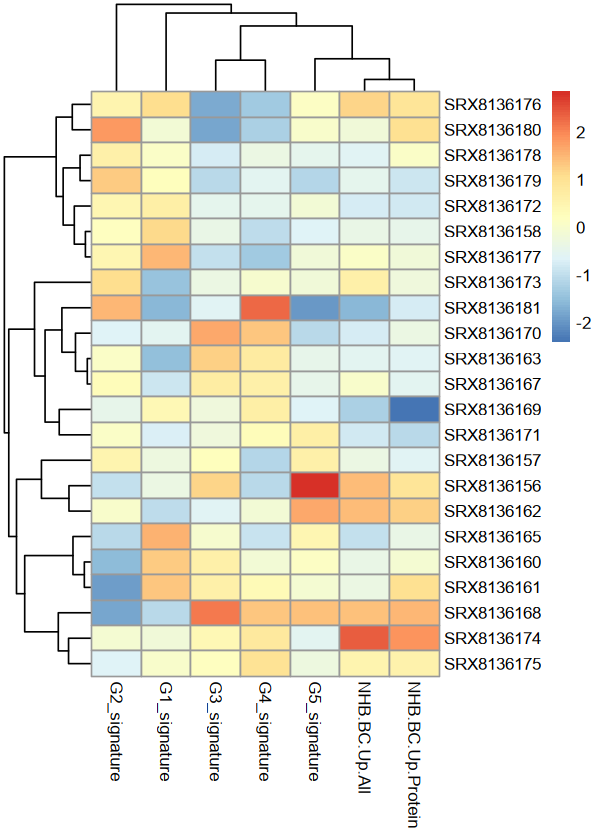

In [3]:
library(pheatmap)
options(repr.plot.width=5, repr.plot.height=7)

cols_sel = c('G1_signature','G2_signature','G3_signature','G4_signature','G5_signature',
             'NHB.BC.Up.All', 'NHB.BC.Up.Protein')

mat <- as.matrix(mg[, cols_sel])


mat_scaled <- scale(mat)
pheatmap(mat_scaled,
         clustering_distance_rows = 'correlation',
         clustering_distance_cols = 'correlation',
         clustering_method = 'average'
        )

corrplot 0.95 loaded



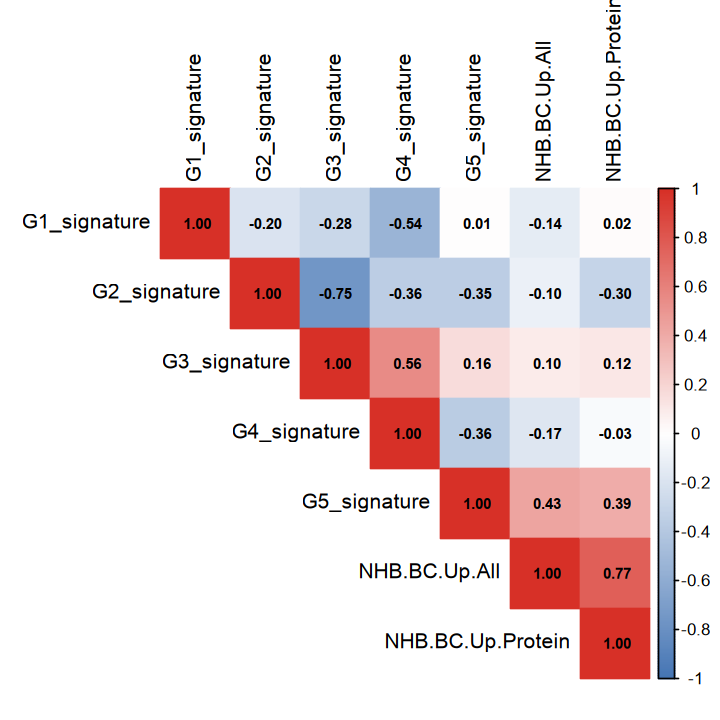

In [4]:
options(repr.plot.width=6, repr.plot.height=6)
library(corrplot)

# Compute Spearman correlation matrix
cor_mat <- cor(mat_scaled, method = "spearman")

# Plot with reversed color (blue for high, red for low/negative)
corrplot(cor_mat,
         method = "color",
         type = "upper",
         col = colorRampPalette(c("#4575B4", "white", "#D73027"))(200),  # reversed!
         tl.col = "black",
         addCoef.col = "black",
         number.cex = 0.7)

Warning message:
“The dot-dot notation (`..r.label..`) was deprecated in ggplot2 3.4.0.
ℹ Please use `after_stat(r.label)` instead.”
`geom_smooth()` using formula = 'y ~ x'


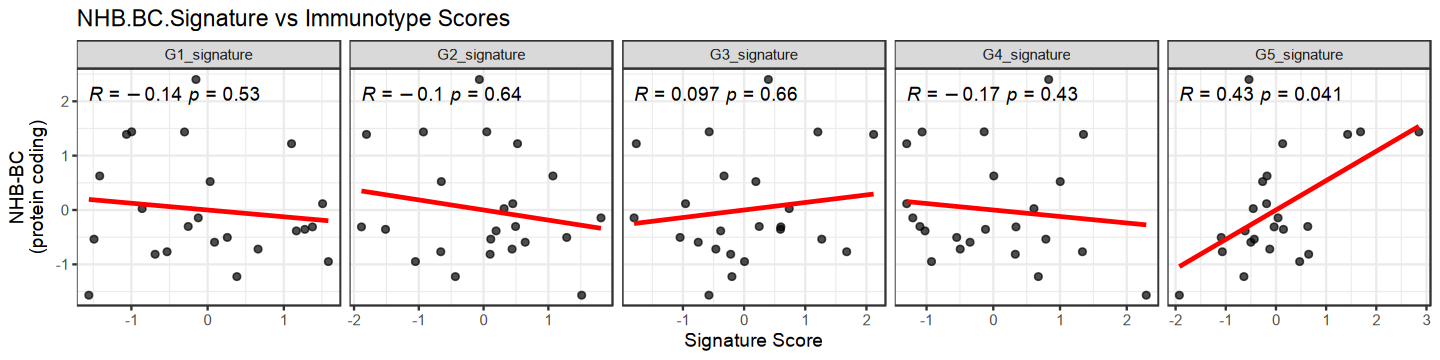

In [6]:
options(repr.plot.width=12, repr.plot.height=3)

library(ggplot2)
library(ggpubr)

score_names = c('G1_signature','G2_signature','G3_signature','G4_signature','G5_signature'
             )


# Make long-format data for easier plotting
library(tidyr)
df_long <- mat_scaled %>% data.frame() %>%
  pivot_longer(
    cols = all_of(score_names),
    names_to = "Signature",
    values_to = "Score"
  )

# Plot using ggplot2 + ggpubr (one panel per signature)
p <- ggplot(df_long, aes(x = Score, y = NHB.BC.Up.All)) +
  geom_point(alpha = 0.7) +
  geom_smooth(method = "lm", se = FALSE, color = "red") +
  stat_cor(aes(label = paste(..r.label.., ..p.label.., sep = "~")), method = "spearman") +
  facet_wrap(~ Signature, scales = "free_x", ncol=5) +
  theme_bw() +
  labs(title = "NHB.BC.Signature vs Immunotype Scores", y = "NHB-BC\n(protein coding)", x = "Signature Score")

print(p)

`geom_smooth()` using formula = 'y ~ x'


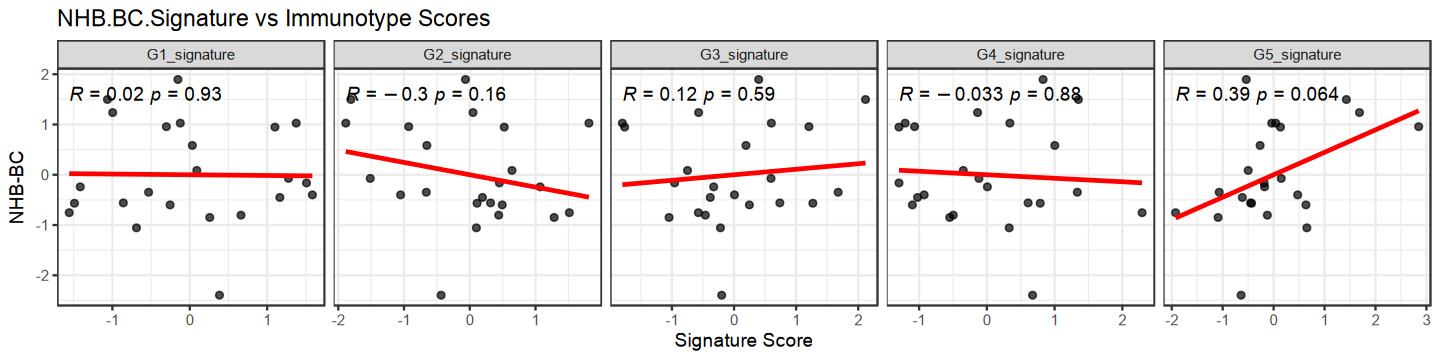

In [7]:
options(repr.plot.width=12, repr.plot.height=3)

library(ggplot2)
library(ggpubr)

score_names = c('G1_signature','G2_signature','G3_signature','G4_signature','G5_signature'
             )


# Make long-format data for easier plotting
library(tidyr)
df_long <- mat_scaled %>% data.frame() %>%
  pivot_longer(
    cols = all_of(score_names),
    names_to = "Signature",
    values_to = "Score"
  )

# Plot using ggplot2 + ggpubr (one panel per signature)
p <- ggplot(df_long, aes(x = Score, y = NHB.BC.Up.Protein)) +
  geom_point(alpha = 0.7) +
  geom_smooth(method = "lm", se = FALSE, color = "red") +
  stat_cor(aes(label = paste(..r.label.., ..p.label.., sep = "~")), method = "spearman") +
  facet_wrap(~ Signature, scales = "free_x", ncol=5) +
  theme_bw() +
  labs(title = "NHB.BC.Signature vs Immunotype Scores", y = "NHB-BC", x = "Signature Score")

print(p)

## Down genes

In [8]:
mg = read.csv('data/09_externalds/gsva_23pt_NhbBcSigDn.csv', 
              row.name=1)
mg

,Sample,Dataset,Sample_type,GSM,G1_signature,G2_signature,G3_signature,G4_signature,G5_signature,NHB.BC.Down.All,NHB.BC.Down.Protein
,<chr>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
SRX8136156,SRX8136156,GSE148892,Whole_blood,GSM4485272,3.915864,3.443940,6.474928,0.6627942,7.487532,8.996205,9.205227
SRX8136157,SRX8136157,GSE148892,Whole_blood,GSM4485273,3.998675,6.074275,5.193996,0.5832359,4.060746,9.070193,9.278564
SRX8136158,SRX8136158,GSE148892,Whole_blood,GSM4485274,6.437120,5.518656,4.352223,0.7701919,2.129005,9.454553,9.693744
SRX8136160,SRX8136160,GSE148892,Whole_blood,GSM4485276,6.628620,2.361768,5.658363,2.9828247,3.310755,9.343766,9.518446
SRX8136161,SRX8136161,GSE148892,Whole_blood,GSM4485277,6.799967,1.674307,5.666059,4.0981414,3.022511,9.178982,9.369990
SRX8136162,SRX8136162,GSE148892,Whole_blood,GSM4485278,2.723668,5.252953,4.100817,2.9339280,5.688330,9.452326,9.603602
SRX8136163,SRX8136163,GSE148892,Whole_blood,GSM4485279,1.874542,5.366436,6.559609,5.1914584,2.409984,9.218135,9.446543
SRX8136165,SRX8136165,GSE148892,Whole_blood,GSM4485281,7.158963,3.215511,4.872542,1.0076999,3.810841,9.232921,9.431646
SRX8136167,SRX8136167,GSE148892,Whole_blood,GSM4485283,2.959670,5.746122,5.848580,4.7556670,2.378611,9.248849,9.461628


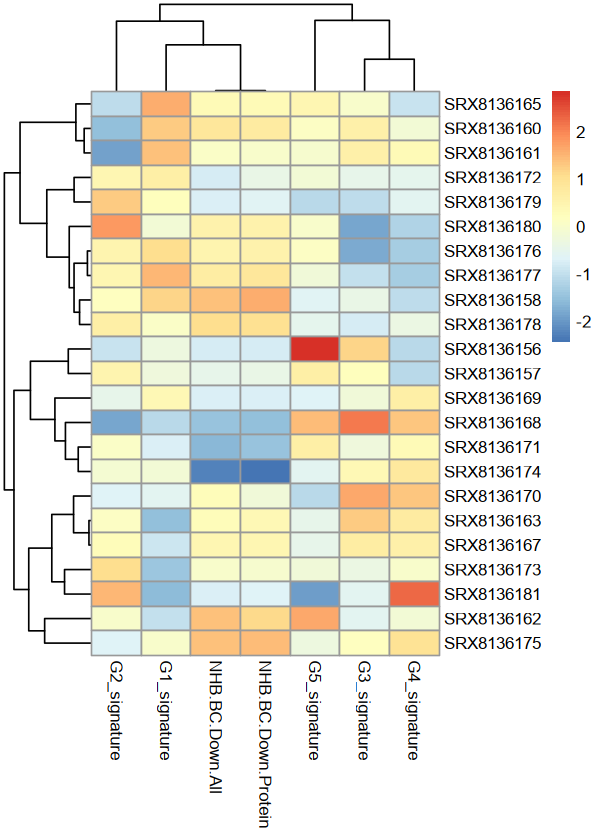

In [10]:
library(pheatmap)
options(repr.plot.width=5, repr.plot.height=7)

cols_sel = c('G1_signature','G2_signature','G3_signature','G4_signature','G5_signature',
             'NHB.BC.Down.All', 'NHB.BC.Down.Protein')

mat <- as.matrix(mg[, cols_sel])


mat_scaled <- scale(mat)
pheatmap(mat_scaled,
         clustering_distance_rows = 'correlation',
         clustering_distance_cols = 'correlation',
         clustering_method = 'average'
        )

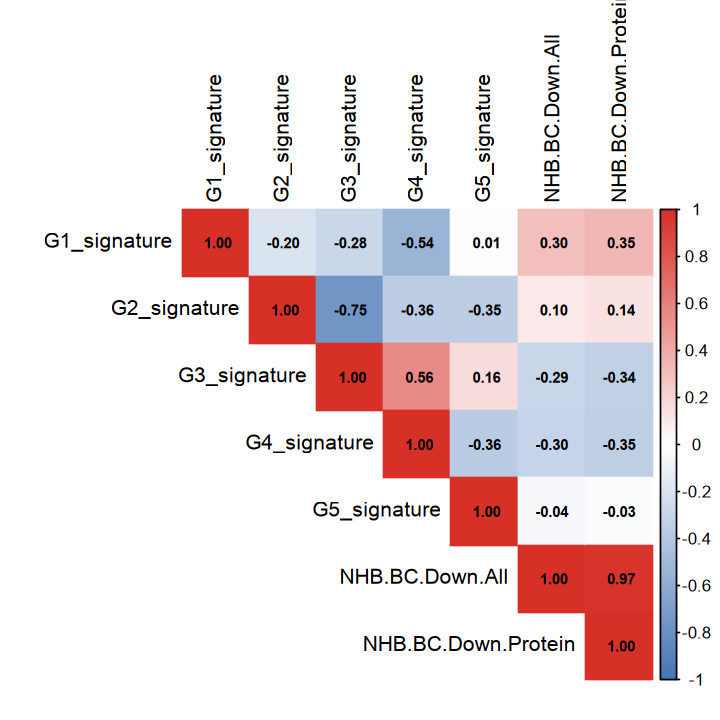

In [11]:
options(repr.plot.width=6, repr.plot.height=6)
library(corrplot)

# Compute Spearman correlation matrix
cor_mat <- cor(mat_scaled, method = "spearman")

# Plot with reversed color (blue for high, red for low/negative)
corrplot(cor_mat,
         method = "color",
         type = "upper",
         col = colorRampPalette(c("#4575B4", "white", "#D73027"))(200),  # reversed!
         tl.col = "black",
         addCoef.col = "black",
         number.cex = 0.7)

`geom_smooth()` using formula = 'y ~ x'


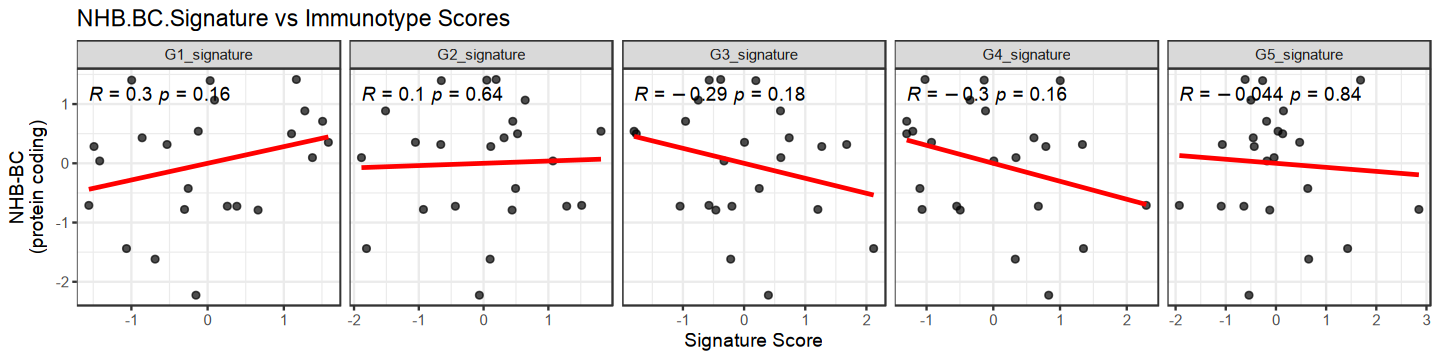

In [12]:
options(repr.plot.width=12, repr.plot.height=3)

library(ggplot2)
library(ggpubr)

score_names = c('G1_signature','G2_signature','G3_signature','G4_signature','G5_signature'
             )


# Make long-format data for easier plotting
library(tidyr)
df_long <- mat_scaled %>% data.frame() %>%
  pivot_longer(
    cols = all_of(score_names),
    names_to = "Signature",
    values_to = "Score"
  )

# Plot using ggplot2 + ggpubr (one panel per signature)
p <- ggplot(df_long, aes(x = Score, y = NHB.BC.Down.All)) +
  geom_point(alpha = 0.7) +
  geom_smooth(method = "lm", se = FALSE, color = "red") +
  stat_cor(aes(label = paste(..r.label.., ..p.label.., sep = "~")), method = "spearman") +
  facet_wrap(~ Signature, scales = "free_x", ncol=5) +
  theme_bw() +
  labs(title = "NHB.BC.Signature vs Immunotype Scores", y = "NHB-BC\n(protein coding)", x = "Signature Score")

print(p)

`geom_smooth()` using formula = 'y ~ x'


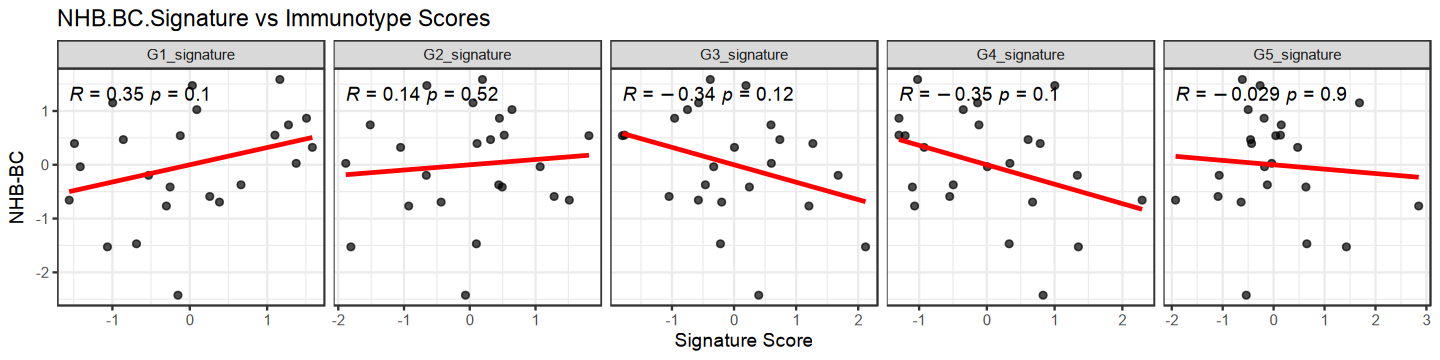

In [13]:
options(repr.plot.width=12, repr.plot.height=3)

library(ggplot2)
library(ggpubr)

score_names = c('G1_signature','G2_signature','G3_signature','G4_signature','G5_signature'
             )


# Make long-format data for easier plotting
library(tidyr)
df_long <- mat_scaled %>% data.frame() %>%
  pivot_longer(
    cols = all_of(score_names),
    names_to = "Signature",
    values_to = "Score"
  )

# Plot using ggplot2 + ggpubr (one panel per signature)
p <- ggplot(df_long, aes(x = Score, y = NHB.BC.Down.Protein)) +
  geom_point(alpha = 0.7) +
  geom_smooth(method = "lm", se = FALSE, color = "red") +
  stat_cor(aes(label = paste(..r.label.., ..p.label.., sep = "~")), method = "spearman") +
  facet_wrap(~ Signature, scales = "free_x", ncol=5) +
  theme_bw() +
  labs(title = "NHB.BC.Signature vs Immunotype Scores", y = "NHB-BC", x = "Signature Score")

print(p)

## Delta

In [14]:
mg = read.csv('data/09_externalds/gsva_23pt_NhbBcSigUp.csv', 
              row.name=1)
mg

,Sample,Dataset,Sample_type,GSM,G1_signature,G2_signature,G3_signature,G4_signature,G5_signature,NHB.BC.Up.All,NHB.BC.Up.Protein
,<chr>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
SRX8136156,SRX8136156,GSE148892,Whole_blood,GSM4485272,3.915864,3.443940,6.474928,0.6627942,7.487532,3.343087,3.685565
SRX8136157,SRX8136157,GSE148892,Whole_blood,GSM4485273,3.998675,6.074275,5.193996,0.5832359,4.060746,3.035975,3.474618
SRX8136158,SRX8136158,GSE148892,Whole_blood,GSM4485274,6.437120,5.518656,4.352223,0.7701919,2.129005,3.021615,3.494688
SRX8136160,SRX8136160,GSE148892,Whole_blood,GSM4485276,6.628620,2.361768,5.658363,2.9828247,3.310755,3.026681,3.546014
SRX8136161,SRX8136161,GSE148892,Whole_blood,GSM4485277,6.799967,1.674307,5.666059,4.0981414,3.022511,3.034603,3.695045
SRX8136162,SRX8136162,GSE148892,Whole_blood,GSM4485278,2.723668,5.252953,4.100817,2.9339280,5.688330,3.343556,3.723555
SRX8136163,SRX8136163,GSE148892,Whole_blood,GSM4485279,1.874542,5.366436,6.559609,5.1914584,2.409984,2.994769,3.479058
SRX8136165,SRX8136165,GSE148892,Whole_blood,GSM4485281,7.158963,3.215511,4.872542,1.0076999,3.810841,2.921954,3.501646
SRX8136167,SRX8136167,GSE148892,Whole_blood,GSM4485283,2.959670,5.746122,5.848580,4.7556670,2.378611,3.094078,3.480007


In [15]:
mg2 = read.csv('data/09_externalds/gsva_23pt_NhbBcSigDn.csv', 
              row.name=1)
mg2

,Sample,Dataset,Sample_type,GSM,G1_signature,G2_signature,G3_signature,G4_signature,G5_signature,NHB.BC.Down.All,NHB.BC.Down.Protein
,<chr>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
SRX8136156,SRX8136156,GSE148892,Whole_blood,GSM4485272,3.915864,3.443940,6.474928,0.6627942,7.487532,8.996205,9.205227
SRX8136157,SRX8136157,GSE148892,Whole_blood,GSM4485273,3.998675,6.074275,5.193996,0.5832359,4.060746,9.070193,9.278564
SRX8136158,SRX8136158,GSE148892,Whole_blood,GSM4485274,6.437120,5.518656,4.352223,0.7701919,2.129005,9.454553,9.693744
SRX8136160,SRX8136160,GSE148892,Whole_blood,GSM4485276,6.628620,2.361768,5.658363,2.9828247,3.310755,9.343766,9.518446
SRX8136161,SRX8136161,GSE148892,Whole_blood,GSM4485277,6.799967,1.674307,5.666059,4.0981414,3.022511,9.178982,9.369990
SRX8136162,SRX8136162,GSE148892,Whole_blood,GSM4485278,2.723668,5.252953,4.100817,2.9339280,5.688330,9.452326,9.603602
SRX8136163,SRX8136163,GSE148892,Whole_blood,GSM4485279,1.874542,5.366436,6.559609,5.1914584,2.409984,9.218135,9.446543
SRX8136165,SRX8136165,GSE148892,Whole_blood,GSM4485281,7.158963,3.215511,4.872542,1.0076999,3.810841,9.232921,9.431646
SRX8136167,SRX8136167,GSE148892,Whole_blood,GSM4485283,2.959670,5.746122,5.848580,4.7556670,2.378611,9.248849,9.461628


In [18]:
stopifnot( all(rownames(mg) == rownames(mg2)) )
print('Index matched')

[1] "Index matched"


In [20]:
mg[,c('NHB.BC.Down.All','NHB.BC.Down.Protein')] = mg2[,c('NHB.BC.Down.All','NHB.BC.Down.Protein')]

mg[,'NHB.BC.Delta.All'] = mg[,'NHB.BC.Up.All'] - mg[,'NHB.BC.Down.All']
mg[,'NHB.BC.Delta.Protein'] = mg[,'NHB.BC.Up.Protein'] - mg[,'NHB.BC.Down.Protein']

mg

,Sample,Dataset,Sample_type,GSM,G1_signature,G2_signature,G3_signature,G4_signature,G5_signature,NHB.BC.Up.All,NHB.BC.Up.Protein,NHB.BC.Down.All,NHB.BC.Down.Protein,NHB.BC.Delta.All,NHB.BC.Delta.Protein
,<chr>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
SRX8136156,SRX8136156,GSE148892,Whole_blood,GSM4485272,3.915864,3.443940,6.474928,0.6627942,7.487532,3.343087,3.685565,8.996205,9.205227,-5.653118,-5.519663
SRX8136157,SRX8136157,GSE148892,Whole_blood,GSM4485273,3.998675,6.074275,5.193996,0.5832359,4.060746,3.035975,3.474618,9.070193,9.278564,-6.034218,-5.803946
SRX8136158,SRX8136158,GSE148892,Whole_blood,GSM4485274,6.437120,5.518656,4.352223,0.7701919,2.129005,3.021615,3.494688,9.454553,9.693744,-6.432938,-6.199056
SRX8136160,SRX8136160,GSE148892,Whole_blood,GSM4485276,6.628620,2.361768,5.658363,2.9828247,3.310755,3.026681,3.546014,9.343766,9.518446,-6.317085,-5.972432
SRX8136161,SRX8136161,GSE148892,Whole_blood,GSM4485277,6.799967,1.674307,5.666059,4.0981414,3.022511,3.034603,3.695045,9.178982,9.369990,-6.144379,-5.674946
SRX8136162,SRX8136162,GSE148892,Whole_blood,GSM4485278,2.723668,5.252953,4.100817,2.9339280,5.688330,3.343556,3.723555,9.452326,9.603602,-6.108770,-5.880046
SRX8136163,SRX8136163,GSE148892,Whole_blood,GSM4485279,1.874542,5.366436,6.559609,5.1914584,2.409984,2.994769,3.479058,9.218135,9.446543,-6.223366,-5.967485
SRX8136165,SRX8136165,GSE148892,Whole_blood,GSM4485281,7.158963,3.215511,4.872542,1.0076999,3.810841,2.921954,3.501646,9.232921,9.431646,-6.310967,-5.930000
SRX8136167,SRX8136167,GSE148892,Whole_blood,GSM4485283,2.959670,5.746122,5.848580,4.7556670,2.378611,3.094078,3.480007,9.248849,9.461628,-6.154771,-5.981621


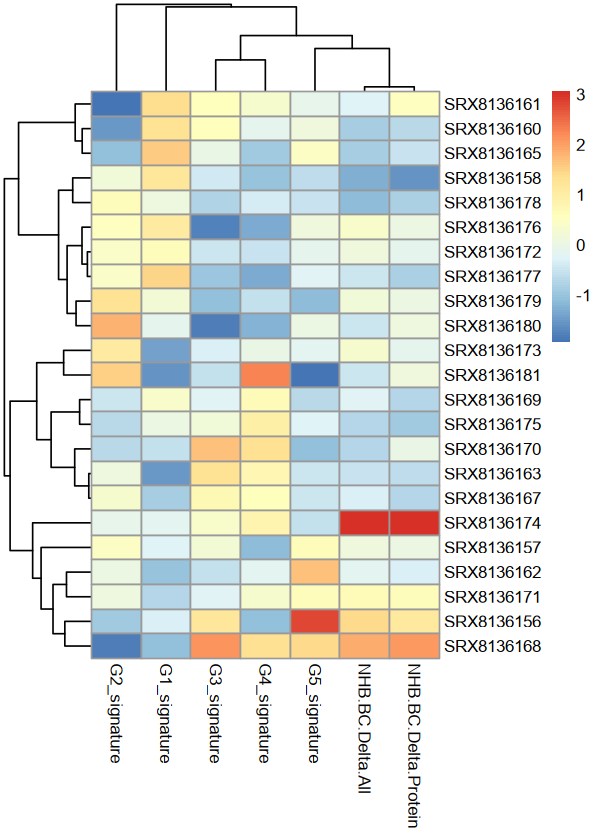

In [21]:
library(pheatmap)
options(repr.plot.width=5, repr.plot.height=7)

cols_sel = c('G1_signature','G2_signature','G3_signature','G4_signature','G5_signature',
             'NHB.BC.Delta.All', 'NHB.BC.Delta.Protein')

mat <- as.matrix(mg[, cols_sel])


mat_scaled <- scale(mat)
pheatmap(mat_scaled,
         clustering_distance_rows = 'correlation',
         clustering_distance_cols = 'correlation',
         clustering_method = 'average'
        )

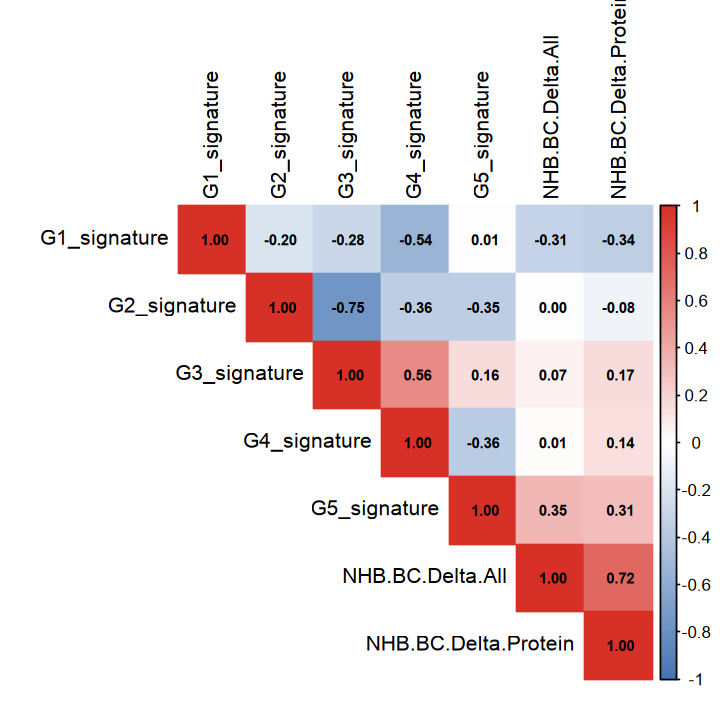

In [22]:
options(repr.plot.width=6, repr.plot.height=6)
library(corrplot)

# Compute Spearman correlation matrix
cor_mat <- cor(mat_scaled, method = "spearman")

# Plot with reversed color (blue for high, red for low/negative)
corrplot(cor_mat,
         method = "color",
         type = "upper",
         col = colorRampPalette(c("#4575B4", "white", "#D73027"))(200),  # reversed!
         tl.col = "black",
         addCoef.col = "black",
         number.cex = 0.7)

`geom_smooth()` using formula = 'y ~ x'


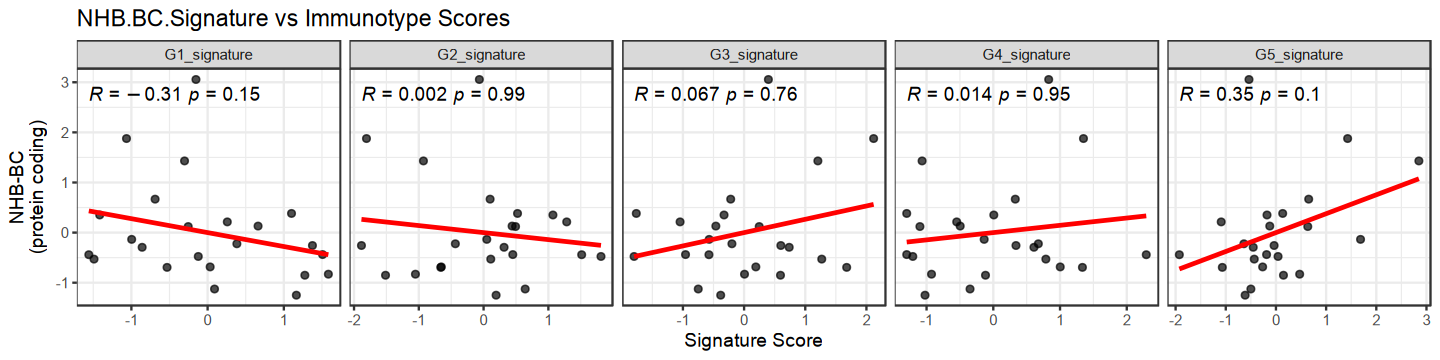

In [23]:
options(repr.plot.width=12, repr.plot.height=3)

library(ggplot2)
library(ggpubr)

score_names = c('G1_signature','G2_signature','G3_signature','G4_signature','G5_signature'
             )


# Make long-format data for easier plotting
library(tidyr)
df_long <- mat_scaled %>% data.frame() %>%
  pivot_longer(
    cols = all_of(score_names),
    names_to = "Signature",
    values_to = "Score"
  )

# Plot using ggplot2 + ggpubr (one panel per signature)
p <- ggplot(df_long, aes(x = Score, y = NHB.BC.Delta.All)) +
  geom_point(alpha = 0.7) +
  geom_smooth(method = "lm", se = FALSE, color = "red") +
  stat_cor(aes(label = paste(..r.label.., ..p.label.., sep = "~")), method = "spearman") +
  facet_wrap(~ Signature, scales = "free_x", ncol=5) +
  theme_bw() +
  labs(title = "NHB.BC.Signature vs Immunotype Scores", y = "NHB-BC\n(protein coding)", x = "Signature Score")

print(p)

`geom_smooth()` using formula = 'y ~ x'


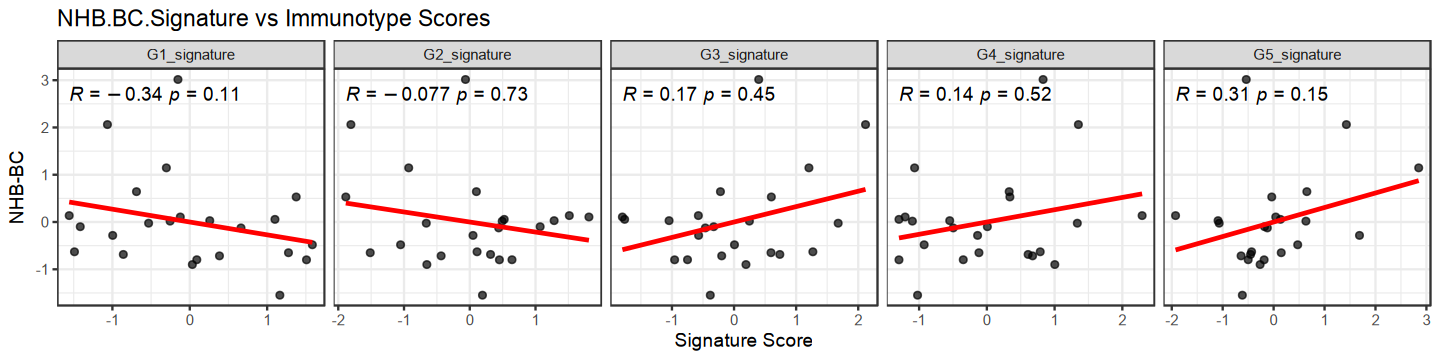

In [24]:
options(repr.plot.width=12, repr.plot.height=3)

library(ggplot2)
library(ggpubr)

score_names = c('G1_signature','G2_signature','G3_signature','G4_signature','G5_signature'
             )


# Make long-format data for easier plotting
library(tidyr)
df_long <- mat_scaled %>% data.frame() %>%
  pivot_longer(
    cols = all_of(score_names),
    names_to = "Signature",
    values_to = "Score"
  )

# Plot using ggplot2 + ggpubr (one panel per signature)
p <- ggplot(df_long, aes(x = Score, y = NHB.BC.Delta.Protein)) +
  geom_point(alpha = 0.7) +
  geom_smooth(method = "lm", se = FALSE, color = "red") +
  stat_cor(aes(label = paste(..r.label.., ..p.label.., sep = "~")), method = "spearman") +
  facet_wrap(~ Signature, scales = "free_x", ncol=5) +
  theme_bw() +
  labs(title = "NHB.BC.Signature vs Immunotype Scores", y = "NHB-BC", x = "Signature Score")

print(p)

# Calc signature score (n=160)

Refer to `codes/44.3`

18k is actually only the breast cancer dataset PBMC

[PAPER](https://pmc.ncbi.nlm.nih.gov/articles/PMC7248369/)


Dear Chelsea, following this conversation, I'm sending the expression data for all 160 open-source blood samples of cancer patients, along with annotation, deconvolution and G signature scores.
TPMs will be sent in a separate email as usual due to Google file size limitation.


Updated files are
- expressions_TPM_allc_blood_samples_opensource_18k
- annotation_allc_blood_samples_opensource_18k.tsv
- deconv_allc_blood_samples_opensource_18k.tsv
- signature_scores_allc_blood_samples_opensource_18k.ts

## Clean data

In [3]:
dpath = 'data/09_externalds/18k_raw'

In [42]:
fname = 'annotation_allc_blood_samples_opensource_18k.tsv'#'18k_bcpt_pbmc_meta.csv'

meta = read.table(glue("{dpath}/{fname}"), 
                 row.names = 1,
                 sep = "\t",
                 header = TRUE)
dim(meta)
meta

[1] 160   5

,Sample,Dataset,Diagnosis,Sample_type,GSM
,<chr>,<chr>,<chr>,<chr>,<chr>
SRX9031276,SRX9031276,GSE157086,Esophageal_Squamous_Cell_Carcinoma,Whole_blood,GSM4752718
SRX9031216,SRX9031216,GSE157086,Colorectal_Adenocarcinoma,Whole_blood,GSM4752674
SRX9031279,SRX9031279,GSE157086,Colon_Adenocarcinoma,Whole_blood,GSM4752721
SRX4780427,SRX4780427,GSE120691,Cervical_cancer,Whole_blood,GSM3408354
SRX8136180,SRX8136180,GSE148892,Breast_Neoplasm,Whole_blood,GSM4485296
SRX6419103,SRX6419103,GSE133998,Breast_Neoplasm,Whole_blood,GSM3932574
SRX9031184,SRX9031184,GSE157086,Meningeal_Neoplasm,Whole_blood,GSM4752642
SRX4780424,SRX4780424,GSE120691,Cervical_cancer,Whole_blood,GSM3408351
SRX4780415,SRX4780415,GSE120691,Cervical_intraepithelial_neoplasia,Whole_blood,GSM3408342


In [43]:
fname = 'signature_scores_allc_blood_samples_opensource_18k.tsv'#'18k_bcpt_pbmc_meta.csv'

scores = read.table(glue("{dpath}/{fname}"), 
                 row.names = 1,
                 sep = "\t",
                 header = TRUE)
dim(scores)
scores

[1] 160   5

,G1_signature,G2_signature,G3_signature,G4_signature,G5_signature
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
SRX9031276,2.012117,1.894695,7.801464,6.5472219,5.406429
SRX9031216,3.936567,6.059113,3.972503,2.8844079,2.920378
SRX9031279,2.418842,1.938041,7.267224,2.8579457,9.798221
SRX4780427,1.825192,3.686779,7.264372,5.0956716,5.149621
SRX8136180,4.225651,8.513783,2.460595,0.3224447,3.144070
SRX6419103,3.305585,6.300544,3.968839,0.1000000,5.136247
SRX9031184,5.251384,4.601810,5.864105,1.5734405,3.590798
SRX4780424,4.541723,5.509023,5.733958,0.6144076,4.110986
SRX4780415,4.859704,3.372117,6.092121,4.1096459,2.526622


In [4]:
fname = 'expressions_TPM_allc_blood_samples_opensource_18k.tsv'

expr = read.table(glue("{dpath}/{fname}"), 
                 row.names = 1,
                 sep = "\t",
                 header = TRUE)
dim(expr)
expr

[1]   160 20062

,A1BG,A1CF,A2M,A2ML1,A3GALT2,A4GALT,A4GNT,AAAS,AACS,AADAC,⋯,ZWINT,ZXDA,ZXDB,ZXDC,ZYG11A,ZYG11B,ZYX,ZZEF1,ZZZ3,pk
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
SRX9031276,0.000000e+00,0.031094886,0.16836820,0.17823268,0.00000000,0.00000000,0.10707574,23.3661862,1.2980813,0.0000000,⋯,0.2522469,1.16268323,1.87576373,8.0634121,0.09069173,3.9514335,1125.89829,18.087699,2.4627444,5.9666479
SRX9031216,9.315055e-02,0.053169774,0.23793542,0.32717989,0.18996134,0.06011076,0.03319086,17.8388106,4.9791335,0.0000000,⋯,4.2381172,1.96993598,3.58429532,17.3404852,0.23098174,6.2938551,1158.03121,23.171330,5.3099799,4.2090588
SRX9031279,0.000000e+00,0.032264517,0.04557015,0.45156358,0.48149620,0.03047254,0.00000000,7.1183269,1.4316221,0.0000000,⋯,0.0000000,0.12677879,0.23333678,9.5852572,0.04438407,1.9151218,2500.23700,11.697931,0.1779269,2.6212942
SRX4780427,0.000000e+00,0.114791995,0.34981345,0.47030466,0.62654974,0.08444289,0.03124178,6.7338695,1.8359060,0.2118709,⋯,1.2977253,0.73147371,1.77505919,12.1295859,0.12048601,2.2442884,763.81819,11.754931,2.3646716,5.1216390
SRX8136180,0.000000e+00,0.000000000,0.07734821,1.25021718,0.79807528,0.00000000,0.00000000,5.1482225,1.8987922,0.0000000,⋯,0.0000000,0.33385773,0.69432742,2.2743340,0.09441973,1.6990190,290.40465,5.277025,0.9083080,1.5873988
SRX6419103,0.000000e+00,0.040114638,2.23647159,0.10408147,0.10045711,0.02777282,0.01025166,1.0334483,0.2807041,0.0000000,⋯,0.1945439,0.32789342,0.45437537,2.6157673,0.06738685,2.3108144,52.43212,2.143538,1.4812869,1.3738774
SRX9031184,4.444182e-02,0.010229734,0.00000000,0.18899771,0.13294699,0.00000000,0.02322903,7.0304595,0.9824917,0.0000000,⋯,0.6746077,0.24167444,0.76363907,2.2377520,0.07304268,1.4399952,938.17049,5.631613,0.5732138,1.2574770
SRX4780424,3.754160e-02,0.012322832,0.08744130,0.17088548,0.22369828,0.07931386,0.00000000,5.0025807,1.0817824,0.0000000,⋯,0.4615708,0.54024907,1.23108822,5.6513859,0.04004633,0.7297813,724.61733,4.843259,0.7324011,0.6671851
SRX4780415,0.000000e+00,0.009150165,0.27299873,0.08039614,0.26895578,0.01560598,0.00000000,4.0264533,1.3270697,0.0000000,⋯,0.4505847,0.56109385,1.14508764,5.6729093,0.03140193,0.6125145,310.11611,4.448514,1.1915945,0.5775629


In [45]:
write.csv(t(expr), glue('{dpath}/clean_expr.csv'))

In [8]:
read_gmt <- function(file_path) {
  # Read all lines from the GMT file
  lines <- readLines(file_path)
  
  # Split each line by tab and store as list
  gmt_list <- strsplit(lines, "\t")
  
  # Create named list: first element is pathway name, third and beyond are genes
  result <- setNames(
    lapply(gmt_list, function(x) x[-c(1:2)]),  # drop pathway name and URL/description
    sapply(gmt_list, function(x) x[1])         # use pathway name as name
  )
  
  return(result)
}


gset = read_gmt('data/08_signature/NHB_up.gmt')
gset

$`NHB-BC Up All`
 [1] "CRYBB2"     "PSPH"       "IGKV1D-17"  "GATD3A"     "LINC02363" 
 [6] "LRPAP1"     "ZBTB24"     "MAP1LC3B"   "S100B"      "MBIP"      
[11] "LMNA"       "SLC9A3"     "SEMA6B"     "SNHG15"     "LY6E-DT"   
[16] "PAIP2"      "KLF3"       "TMEM123"    "RNF11"      "FAM3A"     
[21] "MTHFD2L"    "NIPBL-DT"   "LRG1"       "TNK2-AS1"   "CLCF1"     
[26] "AC083843.2" "ZNF394"     "TIPARP"     "MAFF"       "C2CD4B"    
[31] "SMAD1"      "LINC00886"  "AC008957.1" "LINC02384"  "LINC00865" 
[36] "JUND"       "NEBL"       "IGKV1D-13"  "UBE2G2"     "AC127526.2"
[41] "ZNF295-AS1" "ABHD12"     "HES4"      

$`NHB-BC Up Protein`
 [1] "CRYBB2"   "PSPH"     "LRPAP1"   "ZBTB24"   "MAP1LC3B" "S100B"   
 [7] "MBIP"     "LMNA"     "SLC9A3"   "SEMA6B"   "PAIP2"    "KLF3"    
[13] "TMEM123"  "RNF11"    "FAM3A"    "MTHFD2L"  "LRG1"     "CLCF1"   
[19] "ZNF394"   "TIPARP"   "MAFF"     "C2CD4B"   "SMAD1"    "JUND"    
[25] "NEBL"     "UBE2G2"   "ABHD12"   "HES4"

In [10]:
length(gset[['NHB-BC Up All']])
length(intersect(
    colnames(expr),
    gset[['NHB-BC Up All']]
))

[1] 43

[1] 28

In [13]:
length(gset[['NHB-BC Up Protein']])
length(intersect(
    colnames(expr),
    gset[['NHB-BC Up Protein']]
))

[1] 28

[1] 28

Thus here results using the 2 genesets are the same (because the expression matrix gene list were shrink by merging so many datasets)

In [14]:
print(intersect(
    colnames(expr),
    gset[['NHB-BC Up All']]
))

 [1] "ABHD12"   "C2CD4B"   "CLCF1"    "CRYBB2"   "FAM3A"    "HES4"    
 [7] "JUND"     "KLF3"     "LMNA"     "LRG1"     "LRPAP1"   "MAFF"    
[13] "MAP1LC3B" "MBIP"     "MTHFD2L"  "NEBL"     "PAIP2"    "PSPH"    
[19] "RNF11"    "S100B"    "SEMA6B"   "SLC9A3"   "SMAD1"    "TIPARP"  
[25] "TMEM123"  "UBE2G2"   "ZBTB24"   "ZNF394"  


In [46]:
scores2 <- scores[rownames(meta), , drop = FALSE]
meta2 <- cbind(meta, scores2)
meta2

,Sample,Dataset,Diagnosis,Sample_type,GSM,G1_signature,G2_signature,G3_signature,G4_signature,G5_signature
,<chr>,<chr>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
SRX9031276,SRX9031276,GSE157086,Esophageal_Squamous_Cell_Carcinoma,Whole_blood,GSM4752718,2.012117,1.894695,7.801464,6.5472219,5.406429
SRX9031216,SRX9031216,GSE157086,Colorectal_Adenocarcinoma,Whole_blood,GSM4752674,3.936567,6.059113,3.972503,2.8844079,2.920378
SRX9031279,SRX9031279,GSE157086,Colon_Adenocarcinoma,Whole_blood,GSM4752721,2.418842,1.938041,7.267224,2.8579457,9.798221
SRX4780427,SRX4780427,GSE120691,Cervical_cancer,Whole_blood,GSM3408354,1.825192,3.686779,7.264372,5.0956716,5.149621
SRX8136180,SRX8136180,GSE148892,Breast_Neoplasm,Whole_blood,GSM4485296,4.225651,8.513783,2.460595,0.3224447,3.144070
SRX6419103,SRX6419103,GSE133998,Breast_Neoplasm,Whole_blood,GSM3932574,3.305585,6.300544,3.968839,0.1000000,5.136247
SRX9031184,SRX9031184,GSE157086,Meningeal_Neoplasm,Whole_blood,GSM4752642,5.251384,4.601810,5.864105,1.5734405,3.590798
SRX4780424,SRX4780424,GSE120691,Cervical_cancer,Whole_blood,GSM3408351,4.541723,5.509023,5.733958,0.6144076,4.110986
SRX4780415,SRX4780415,GSE120691,Cervical_intraepithelial_neoplasia,Whole_blood,GSM3408342,4.859704,3.372117,6.092121,4.1096459,2.526622


In [47]:
write.csv(meta2, glue('{dpath}/clean_meta.csv'))

Run this in R console - this jupyter with R kernel is weird b/c kernel dies when library(GSVA)

module load gcc/14.2.0 R/4.4.2

Open an R session and run

```R
library(GSVA)
library(GSEABase)
library(glue)

setwd('/n/data1/dfci/surgonc/mittendorf/lab/chelsea/iw/github')
#--------------- load geneset 
gmt_file <- "data/08_signature/NHB_dn.gmt" # gmt_file <- "data/08_signature/NHB_dn.gmt"
gsets <- getGmt(gmt_file)

#--------------- load meta and dat
dpath = 'data/09_externalds/18k_raw'
meta3 = read.csv(glue('{dpath}/clean_meta.csv'), row.names=1)
dat3 = read.csv(glue('{dpath}/clean_expr.csv'), row.names=1)

pheno_data <- AnnotatedDataFrame(data = meta3)
eset <- ExpressionSet(
  assayData = as.matrix(dat3),  # Expression data matrix
  phenoData = pheno_data                   # Phenotype data
)

experimentData(eset) <- MIAME(
  name = "ex23",
)

#--------------- calc ssgsea
ssgsea = ssgseaParam(eset, gsets)

ssgsea_out = gsva(ssgsea)
ssgsea_out_t = t(exprs(ssgsea_out))


#--------------- merge ssgsea output and meta data
mg <- merge(meta3, ssgsea_out_t, by = "row.names")
rownames(mg) <- mg$Row.names
mg$Row.names <- NULL

write.csv(mg, 'data/09_externalds/18k_clean/gsva_160pt_NhbBcSigDn.csv')

```

## Up genes

In [48]:
mg = read.csv('data/09_externalds/18k_clean/gsva_160pt_NhbBcSigUp.csv', 
              row.name=1)
mg

,Sample,Dataset,Diagnosis,Sample_type,GSM,G1_signature,G2_signature,G3_signature,G4_signature,G5_signature,NHB.BC.Up.All,NHB.BC.Up.Protein
,<chr>,<chr>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
SRX3146378,SRX3146378,GSE103305,Thyroid_Neoplasm,Whole_blood,GSM2760044,5.707469,1.934101,9.561733,5.2320930,0.8826712,1.2076814,1.2076814
SRX3146379,SRX3146379,GSE103305,Thyroid_Neoplasm,Whole_blood,GSM2760045,6.040090,2.707472,4.838370,6.6767854,1.8362929,1.2142249,1.2142249
SRX3146380,SRX3146380,GSE103305,Thyroid_Neoplasm,Whole_blood,GSM2760046,5.281971,5.016304,5.908280,3.5297707,1.1403813,1.2613131,1.2613131
SRX3146381,SRX3146381,GSE103305,Thyroid_Neoplasm,Whole_blood,GSM2760047,3.518146,2.653013,6.720693,5.4872123,4.3834094,1.3911064,1.3911064
SRX3146382,SRX3146382,GSE103305,Thyroid_Neoplasm,Whole_blood,GSM2760048,4.987088,6.501059,2.738035,2.2148570,2.7959626,0.8952005,0.8952005
SRX3146383,SRX3146383,GSE103305,Thyroid_Neoplasm,Whole_blood,GSM2760049,2.758298,7.286711,4.350535,5.8176612,0.1000000,1.1400126,1.1400126
SRX3146384,SRX3146384,GSE103305,Thyroid_Neoplasm,Whole_blood,GSM2760050,5.710118,2.411157,7.111270,4.1996426,2.4436346,1.4145077,1.4145077
SRX3146385,SRX3146385,GSE103305,Thyroid_Neoplasm,Whole_blood,GSM2760051,5.346418,2.881061,5.329568,5.2533747,2.4113092,1.1647657,1.1647657
SRX3146386,SRX3146386,GSE103305,Thyroid_Neoplasm,Whole_blood,GSM2760052,4.592317,2.259724,7.732459,3.8073111,4.4530452,1.3010209,1.3010209


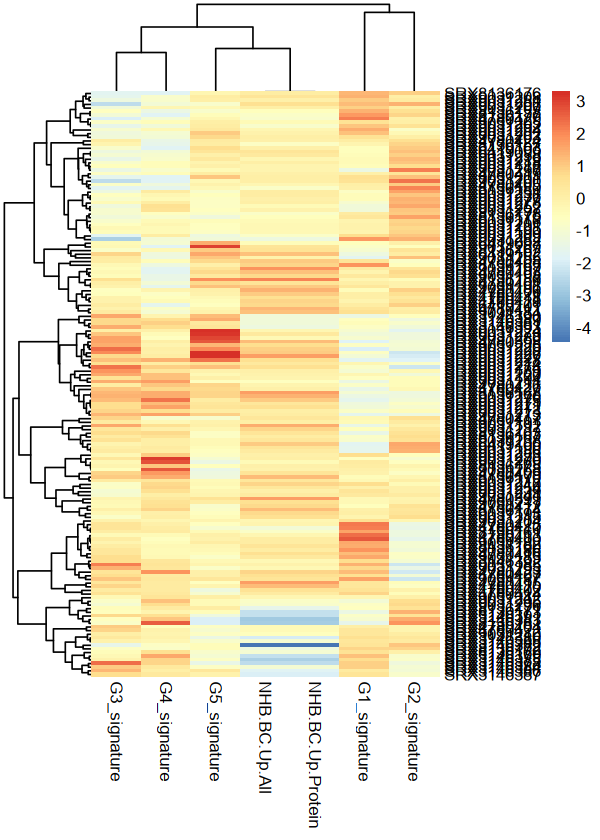

In [49]:
library(pheatmap)
options(repr.plot.width=5, repr.plot.height=7)

cols_sel = c('G1_signature','G2_signature','G3_signature','G4_signature','G5_signature',
             'NHB.BC.Up.All', 'NHB.BC.Up.Protein')

mat <- as.matrix(mg[, cols_sel])


mat_scaled <- scale(mat)
pheatmap(mat_scaled,
         clustering_distance_rows = 'correlation',
         clustering_distance_cols = 'correlation',
         clustering_method = 'average'
        )

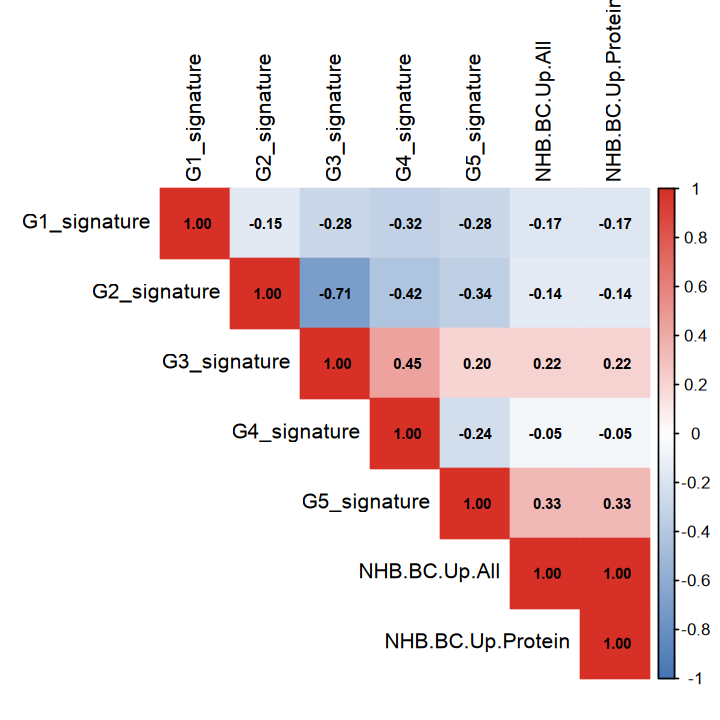

In [50]:
options(repr.plot.width=6, repr.plot.height=6)
library(corrplot)

# Compute Spearman correlation matrix
cor_mat <- cor(mat_scaled, method = "spearman")

# Plot with reversed color (blue for high, red for low/negative)
corrplot(cor_mat,
         method = "color",
         type = "upper",
         col = colorRampPalette(c("#4575B4", "white", "#D73027"))(200),  # reversed!
         tl.col = "black",
         addCoef.col = "black",
         number.cex = 0.7)

`geom_smooth()` using formula = 'y ~ x'


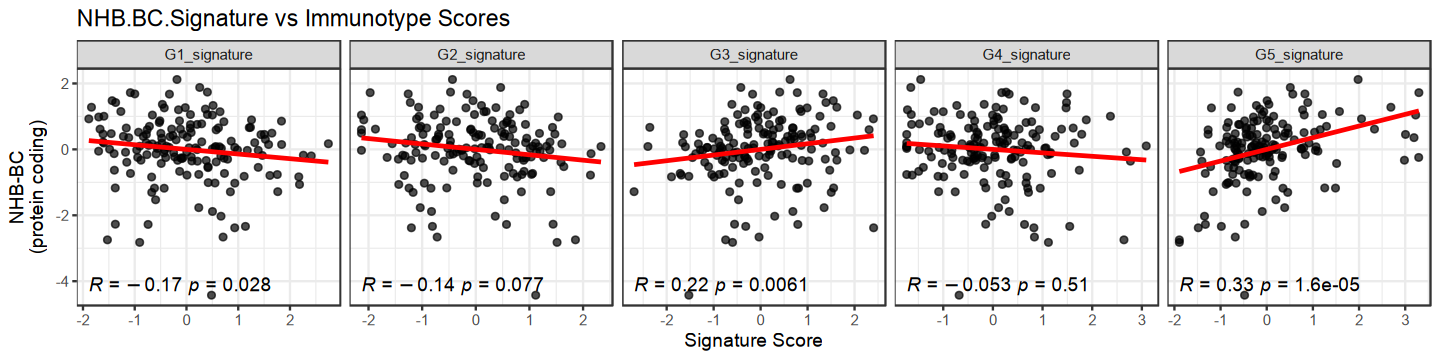

In [52]:
options(repr.plot.width=12, repr.plot.height=3)

library(ggplot2)
library(ggpubr)

score_names = c('G1_signature','G2_signature','G3_signature','G4_signature','G5_signature'
             )


# Make long-format data for easier plotting
library(tidyr)
df_long <- mat_scaled %>% data.frame() %>%
  pivot_longer(
    cols = all_of(score_names),
    names_to = "Signature",
    values_to = "Score"
  )

# Plot using ggplot2 + ggpubr (one panel per signature)
p <- ggplot(df_long, aes(x = Score, y = NHB.BC.Up.All)) +
  geom_point(alpha = 0.7) +
  geom_smooth(method = "lm", se = FALSE, color = "red") +
  stat_cor(
    aes(label = paste(..r.label.., ..p.label.., sep = "~")),
    method = "spearman",
    label.x.npc = "left",   # x position: left side
    label.y.npc = "bottom", # y position: bottom
    hjust = 0, vjust = 0    # align to bottom-left
  ) +
  facet_wrap(~ Signature, scales = "free_x", ncol = 5) +
  theme_bw() +
  labs(
    title = "NHB.BC.Signature vs Immunotype Scores",
    y = "NHB-BC\n(protein coding)",
    x = "Signature Score"
  )

print(p)

`geom_smooth()` using formula = 'y ~ x'


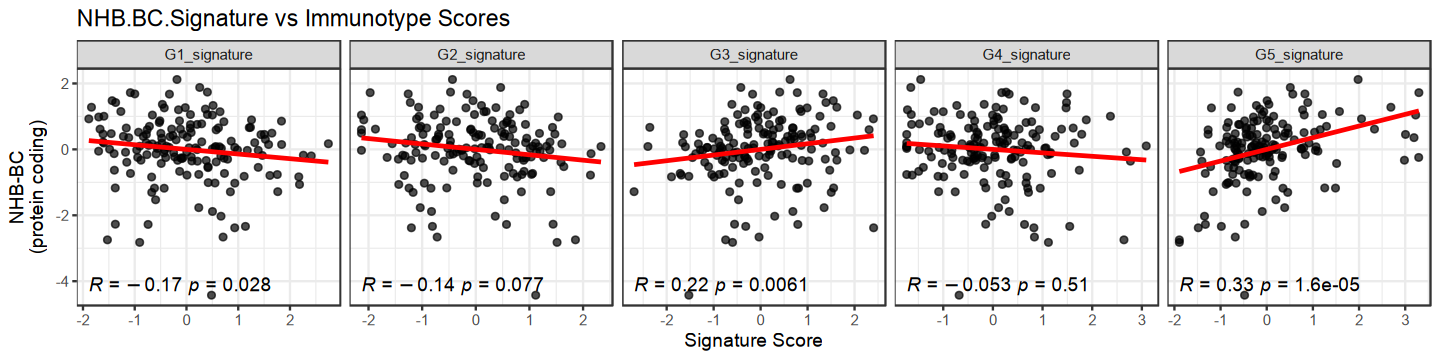

In [53]:
options(repr.plot.width=12, repr.plot.height=3)

library(ggplot2)
library(ggpubr)

score_names = c('G1_signature','G2_signature','G3_signature','G4_signature','G5_signature'
             )


# Make long-format data for easier plotting
library(tidyr)
df_long <- mat_scaled %>% data.frame() %>%
  pivot_longer(
    cols = all_of(score_names),
    names_to = "Signature",
    values_to = "Score"
  )

# Plot using ggplot2 + ggpubr (one panel per signature)
p <- ggplot(df_long, aes(x = Score, y = NHB.BC.Up.Protein)) +
  geom_point(alpha = 0.7) +
  geom_smooth(method = "lm", se = FALSE, color = "red") +
  stat_cor(
    aes(label = paste(..r.label.., ..p.label.., sep = "~")),
    method = "spearman",
    label.x.npc = "left",   # x position: left side
    label.y.npc = "bottom", # y position: bottom
    hjust = 0, vjust = 0    # align to bottom-left
  ) +
  facet_wrap(~ Signature, scales = "free_x", ncol = 5) +
  theme_bw() +
  labs(
    title = "NHB.BC.Signature vs Immunotype Scores",
    y = "NHB-BC\n(protein coding)",
    x = "Signature Score"
  )

print(p)

## Down genes

In [54]:
mg = read.csv('data/09_externalds/18k_clean/gsva_160pt_NhbBcSigDn.csv', 
              row.name=1)
mg

,Sample,Dataset,Diagnosis,Sample_type,GSM,G1_signature,G2_signature,G3_signature,G4_signature,G5_signature,NHB.BC.Down.All,NHB.BC.Down.Protein
,<chr>,<chr>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
SRX3146378,SRX3146378,GSE103305,Thyroid_Neoplasm,Whole_blood,GSM2760044,5.707469,1.934101,9.561733,5.2320930,0.8826712,1.2837033,1.3413879
SRX3146379,SRX3146379,GSE103305,Thyroid_Neoplasm,Whole_blood,GSM2760045,6.040090,2.707472,4.838370,6.6767854,1.8362929,1.1194847,1.2055385
SRX3146380,SRX3146380,GSE103305,Thyroid_Neoplasm,Whole_blood,GSM2760046,5.281971,5.016304,5.908280,3.5297707,1.1403813,1.1424840,1.2036866
SRX3146381,SRX3146381,GSE103305,Thyroid_Neoplasm,Whole_blood,GSM2760047,3.518146,2.653013,6.720693,5.4872123,4.3834094,1.2175429,1.2686965
SRX3146382,SRX3146382,GSE103305,Thyroid_Neoplasm,Whole_blood,GSM2760048,4.987088,6.501059,2.738035,2.2148570,2.7959626,1.1665804,1.2536760
SRX3146383,SRX3146383,GSE103305,Thyroid_Neoplasm,Whole_blood,GSM2760049,2.758298,7.286711,4.350535,5.8176612,0.1000000,1.2424787,1.2739021
SRX3146384,SRX3146384,GSE103305,Thyroid_Neoplasm,Whole_blood,GSM2760050,5.710118,2.411157,7.111270,4.1996426,2.4436346,0.9320767,0.9942504
SRX3146385,SRX3146385,GSE103305,Thyroid_Neoplasm,Whole_blood,GSM2760051,5.346418,2.881061,5.329568,5.2533747,2.4113092,1.0461089,1.1204771
SRX3146386,SRX3146386,GSE103305,Thyroid_Neoplasm,Whole_blood,GSM2760052,4.592317,2.259724,7.732459,3.8073111,4.4530452,1.1228973,1.1724117


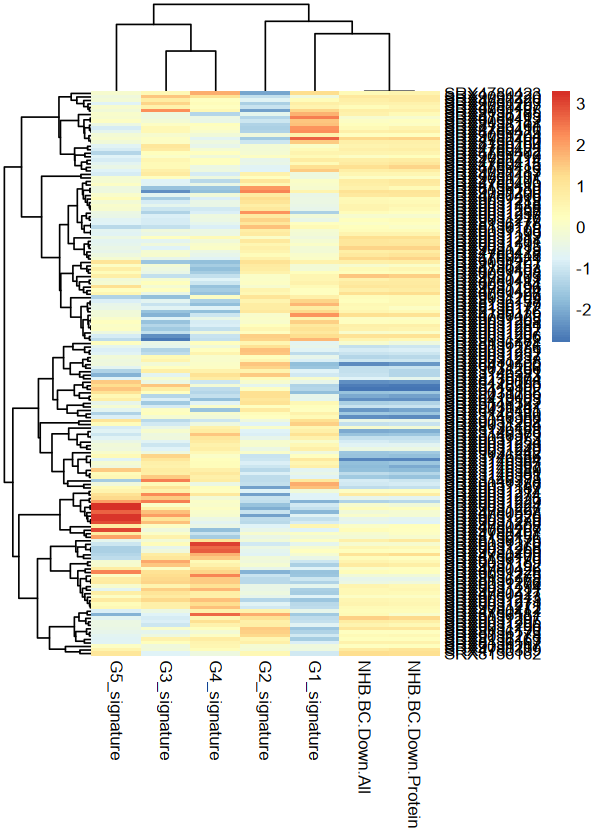

In [55]:
library(pheatmap)
options(repr.plot.width=5, repr.plot.height=7)

cols_sel = c('G1_signature','G2_signature','G3_signature','G4_signature','G5_signature',
             'NHB.BC.Down.All', 'NHB.BC.Down.Protein')

mat <- as.matrix(mg[, cols_sel])


mat_scaled <- scale(mat)
pheatmap(mat_scaled,
         clustering_distance_rows = 'correlation',
         clustering_distance_cols = 'correlation',
         clustering_method = 'average'
        )

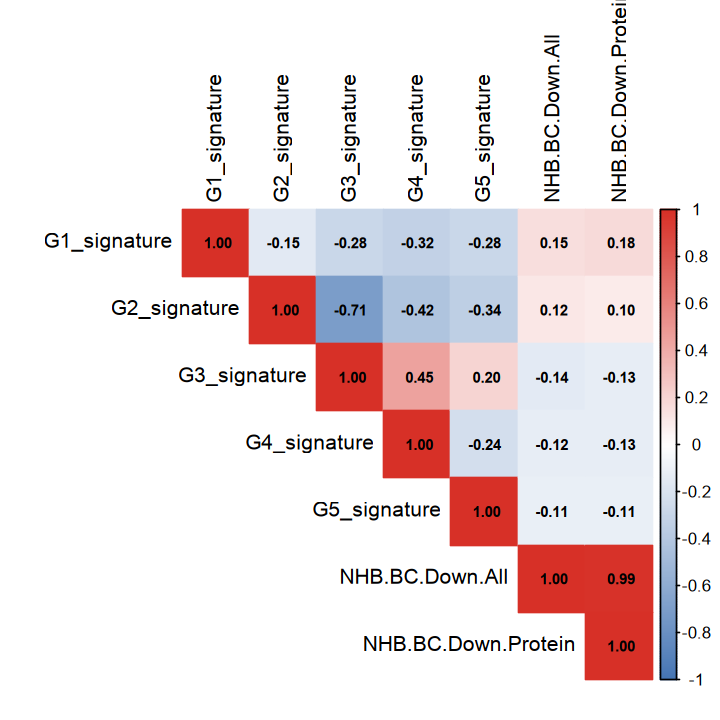

In [56]:
options(repr.plot.width=6, repr.plot.height=6)
library(corrplot)

# Compute Spearman correlation matrix
cor_mat <- cor(mat_scaled, method = "spearman")

# Plot with reversed color (blue for high, red for low/negative)
corrplot(cor_mat,
         method = "color",
         type = "upper",
         col = colorRampPalette(c("#4575B4", "white", "#D73027"))(200),  # reversed!
         tl.col = "black",
         addCoef.col = "black",
         number.cex = 0.7)

`geom_smooth()` using formula = 'y ~ x'


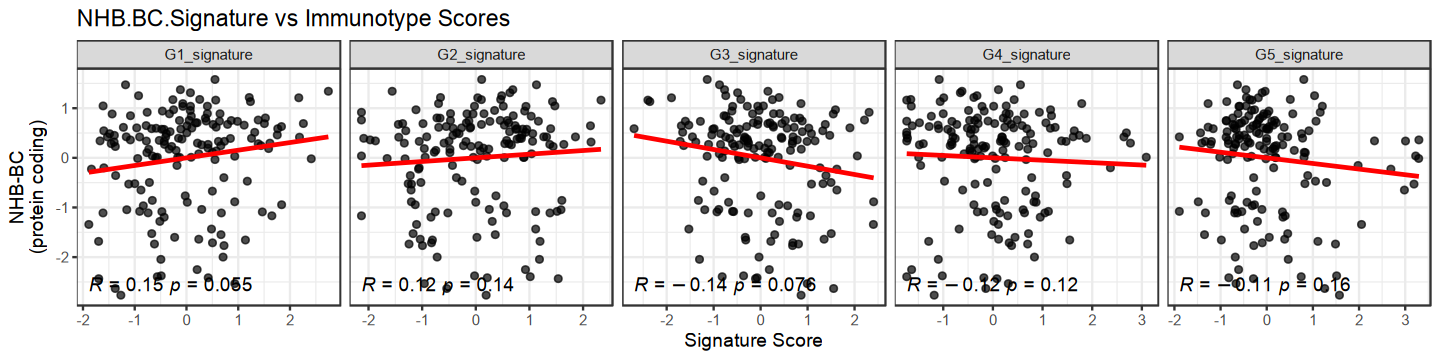

In [58]:
options(repr.plot.width=12, repr.plot.height=3)

library(ggplot2)
library(ggpubr)

score_names = c('G1_signature','G2_signature','G3_signature','G4_signature','G5_signature'
             )


# Make long-format data for easier plotting
library(tidyr)
df_long <- mat_scaled %>% data.frame() %>%
  pivot_longer(
    cols = all_of(score_names),
    names_to = "Signature",
    values_to = "Score"
  )

# Plot using ggplot2 + ggpubr (one panel per signature)
p <- ggplot(df_long, aes(x = Score, y = NHB.BC.Down.All)) +
  geom_point(alpha = 0.7) +
  geom_smooth(method = "lm", se = FALSE, color = "red") +
  stat_cor(
    aes(label = paste(..r.label.., ..p.label.., sep = "~")),
    method = "spearman",
    label.x.npc = "left",   # x position: left side
    label.y.npc = "bottom", # y position: bottom
    hjust = 0, vjust = 0    # align to bottom-left
  ) +
  facet_wrap(~ Signature, scales = "free_x", ncol = 5) +
  theme_bw() +
  labs(
    title = "NHB.BC.Signature vs Immunotype Scores",
    y = "NHB-BC\n(protein coding)",
    x = "Signature Score"
  )

print(p)

`geom_smooth()` using formula = 'y ~ x'


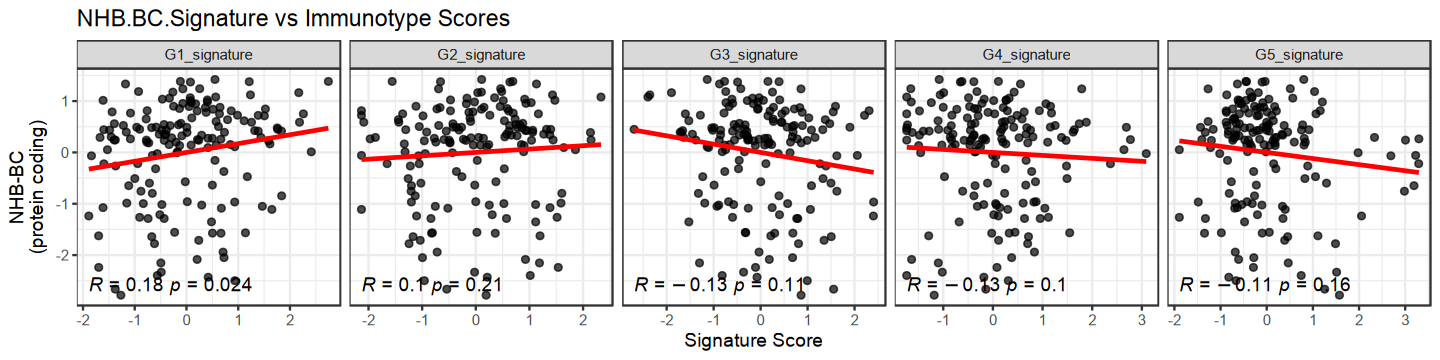

In [59]:
options(repr.plot.width=12, repr.plot.height=3)

library(ggplot2)
library(ggpubr)

score_names = c('G1_signature','G2_signature','G3_signature','G4_signature','G5_signature'
             )


# Make long-format data for easier plotting
library(tidyr)
df_long <- mat_scaled %>% data.frame() %>%
  pivot_longer(
    cols = all_of(score_names),
    names_to = "Signature",
    values_to = "Score"
  )

# Plot using ggplot2 + ggpubr (one panel per signature)
p <- ggplot(df_long, aes(x = Score, y = NHB.BC.Down.Protein)) +
  geom_point(alpha = 0.7) +
  geom_smooth(method = "lm", se = FALSE, color = "red") +
  stat_cor(
    aes(label = paste(..r.label.., ..p.label.., sep = "~")),
    method = "spearman",
    label.x.npc = "left",   # x position: left side
    label.y.npc = "bottom", # y position: bottom
    hjust = 0, vjust = 0    # align to bottom-left
  ) +
  facet_wrap(~ Signature, scales = "free_x", ncol = 5) +
  theme_bw() +
  labs(
    title = "NHB.BC.Signature vs Immunotype Scores",
    y = "NHB-BC\n(protein coding)",
    x = "Signature Score"
  )

print(p)

## Delta

In [14]:
mg = read.csv('data/09_externalds/gsva_23pt_NhbBcSigUp.csv', 
              row.name=1)
mg

,Sample,Dataset,Sample_type,GSM,G1_signature,G2_signature,G3_signature,G4_signature,G5_signature,NHB.BC.Up.All,NHB.BC.Up.Protein
,<chr>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
SRX8136156,SRX8136156,GSE148892,Whole_blood,GSM4485272,3.915864,3.443940,6.474928,0.6627942,7.487532,3.343087,3.685565
SRX8136157,SRX8136157,GSE148892,Whole_blood,GSM4485273,3.998675,6.074275,5.193996,0.5832359,4.060746,3.035975,3.474618
SRX8136158,SRX8136158,GSE148892,Whole_blood,GSM4485274,6.437120,5.518656,4.352223,0.7701919,2.129005,3.021615,3.494688
SRX8136160,SRX8136160,GSE148892,Whole_blood,GSM4485276,6.628620,2.361768,5.658363,2.9828247,3.310755,3.026681,3.546014
SRX8136161,SRX8136161,GSE148892,Whole_blood,GSM4485277,6.799967,1.674307,5.666059,4.0981414,3.022511,3.034603,3.695045
SRX8136162,SRX8136162,GSE148892,Whole_blood,GSM4485278,2.723668,5.252953,4.100817,2.9339280,5.688330,3.343556,3.723555
SRX8136163,SRX8136163,GSE148892,Whole_blood,GSM4485279,1.874542,5.366436,6.559609,5.1914584,2.409984,2.994769,3.479058
SRX8136165,SRX8136165,GSE148892,Whole_blood,GSM4485281,7.158963,3.215511,4.872542,1.0076999,3.810841,2.921954,3.501646
SRX8136167,SRX8136167,GSE148892,Whole_blood,GSM4485283,2.959670,5.746122,5.848580,4.7556670,2.378611,3.094078,3.480007


In [15]:
mg2 = read.csv('data/09_externalds/gsva_23pt_NhbBcSigDn.csv', 
              row.name=1)
mg2

,Sample,Dataset,Sample_type,GSM,G1_signature,G2_signature,G3_signature,G4_signature,G5_signature,NHB.BC.Down.All,NHB.BC.Down.Protein
,<chr>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
SRX8136156,SRX8136156,GSE148892,Whole_blood,GSM4485272,3.915864,3.443940,6.474928,0.6627942,7.487532,8.996205,9.205227
SRX8136157,SRX8136157,GSE148892,Whole_blood,GSM4485273,3.998675,6.074275,5.193996,0.5832359,4.060746,9.070193,9.278564
SRX8136158,SRX8136158,GSE148892,Whole_blood,GSM4485274,6.437120,5.518656,4.352223,0.7701919,2.129005,9.454553,9.693744
SRX8136160,SRX8136160,GSE148892,Whole_blood,GSM4485276,6.628620,2.361768,5.658363,2.9828247,3.310755,9.343766,9.518446
SRX8136161,SRX8136161,GSE148892,Whole_blood,GSM4485277,6.799967,1.674307,5.666059,4.0981414,3.022511,9.178982,9.369990
SRX8136162,SRX8136162,GSE148892,Whole_blood,GSM4485278,2.723668,5.252953,4.100817,2.9339280,5.688330,9.452326,9.603602
SRX8136163,SRX8136163,GSE148892,Whole_blood,GSM4485279,1.874542,5.366436,6.559609,5.1914584,2.409984,9.218135,9.446543
SRX8136165,SRX8136165,GSE148892,Whole_blood,GSM4485281,7.158963,3.215511,4.872542,1.0076999,3.810841,9.232921,9.431646
SRX8136167,SRX8136167,GSE148892,Whole_blood,GSM4485283,2.959670,5.746122,5.848580,4.7556670,2.378611,9.248849,9.461628


In [18]:
stopifnot( all(rownames(mg) == rownames(mg2)) )
print('Index matched')

[1] "Index matched"


In [20]:
mg[,c('NHB.BC.Down.All','NHB.BC.Down.Protein')] = mg2[,c('NHB.BC.Down.All','NHB.BC.Down.Protein')]

mg[,'NHB.BC.Delta.All'] = mg[,'NHB.BC.Up.All'] - mg[,'NHB.BC.Down.All']
mg[,'NHB.BC.Delta.Protein'] = mg[,'NHB.BC.Up.Protein'] - mg[,'NHB.BC.Down.Protein']

mg

,Sample,Dataset,Sample_type,GSM,G1_signature,G2_signature,G3_signature,G4_signature,G5_signature,NHB.BC.Up.All,NHB.BC.Up.Protein,NHB.BC.Down.All,NHB.BC.Down.Protein,NHB.BC.Delta.All,NHB.BC.Delta.Protein
,<chr>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
SRX8136156,SRX8136156,GSE148892,Whole_blood,GSM4485272,3.915864,3.443940,6.474928,0.6627942,7.487532,3.343087,3.685565,8.996205,9.205227,-5.653118,-5.519663
SRX8136157,SRX8136157,GSE148892,Whole_blood,GSM4485273,3.998675,6.074275,5.193996,0.5832359,4.060746,3.035975,3.474618,9.070193,9.278564,-6.034218,-5.803946
SRX8136158,SRX8136158,GSE148892,Whole_blood,GSM4485274,6.437120,5.518656,4.352223,0.7701919,2.129005,3.021615,3.494688,9.454553,9.693744,-6.432938,-6.199056
SRX8136160,SRX8136160,GSE148892,Whole_blood,GSM4485276,6.628620,2.361768,5.658363,2.9828247,3.310755,3.026681,3.546014,9.343766,9.518446,-6.317085,-5.972432
SRX8136161,SRX8136161,GSE148892,Whole_blood,GSM4485277,6.799967,1.674307,5.666059,4.0981414,3.022511,3.034603,3.695045,9.178982,9.369990,-6.144379,-5.674946
SRX8136162,SRX8136162,GSE148892,Whole_blood,GSM4485278,2.723668,5.252953,4.100817,2.9339280,5.688330,3.343556,3.723555,9.452326,9.603602,-6.108770,-5.880046
SRX8136163,SRX8136163,GSE148892,Whole_blood,GSM4485279,1.874542,5.366436,6.559609,5.1914584,2.409984,2.994769,3.479058,9.218135,9.446543,-6.223366,-5.967485
SRX8136165,SRX8136165,GSE148892,Whole_blood,GSM4485281,7.158963,3.215511,4.872542,1.0076999,3.810841,2.921954,3.501646,9.232921,9.431646,-6.310967,-5.930000
SRX8136167,SRX8136167,GSE148892,Whole_blood,GSM4485283,2.959670,5.746122,5.848580,4.7556670,2.378611,3.094078,3.480007,9.248849,9.461628,-6.154771,-5.981621


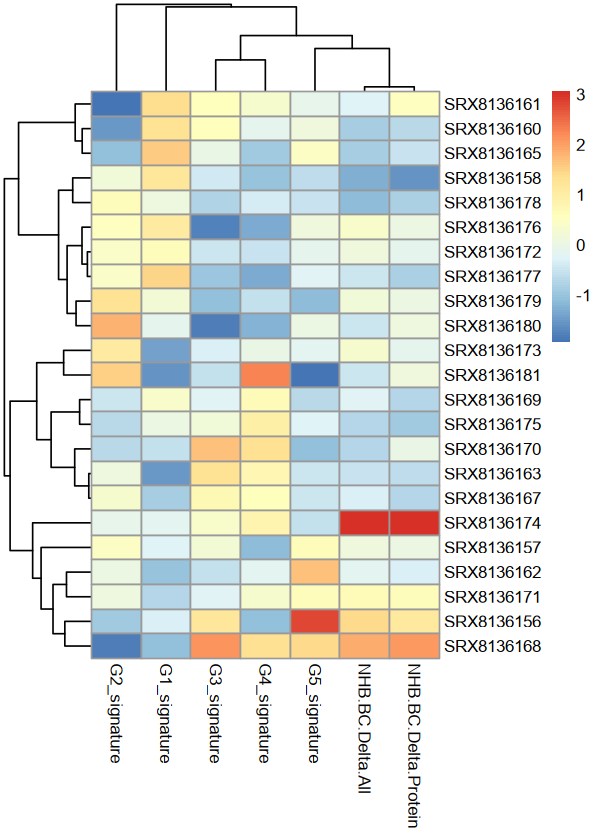

In [21]:
library(pheatmap)
options(repr.plot.width=5, repr.plot.height=7)

cols_sel = c('G1_signature','G2_signature','G3_signature','G4_signature','G5_signature',
             'NHB.BC.Delta.All', 'NHB.BC.Delta.Protein')

mat <- as.matrix(mg[, cols_sel])


mat_scaled <- scale(mat)
pheatmap(mat_scaled,
         clustering_distance_rows = 'correlation',
         clustering_distance_cols = 'correlation',
         clustering_method = 'average'
        )

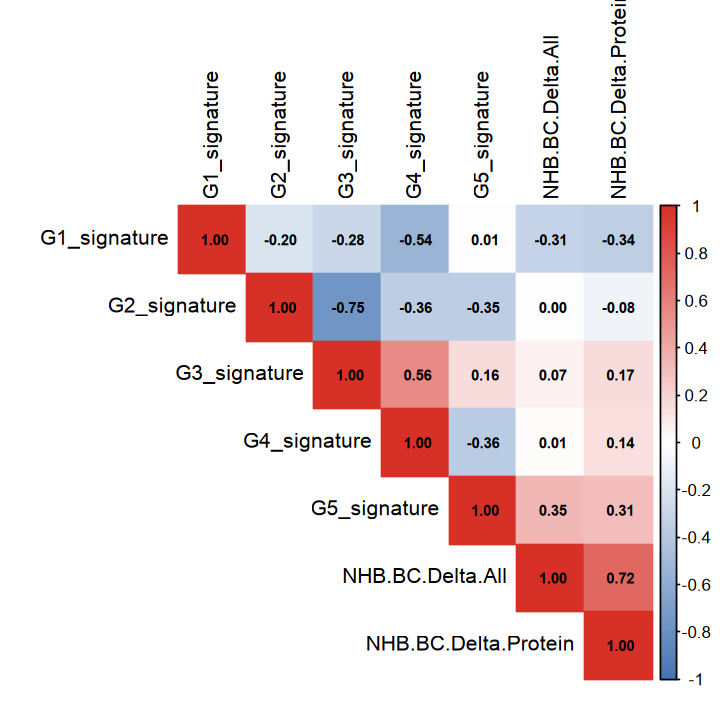

In [22]:
options(repr.plot.width=6, repr.plot.height=6)
library(corrplot)

# Compute Spearman correlation matrix
cor_mat <- cor(mat_scaled, method = "spearman")

# Plot with reversed color (blue for high, red for low/negative)
corrplot(cor_mat,
         method = "color",
         type = "upper",
         col = colorRampPalette(c("#4575B4", "white", "#D73027"))(200),  # reversed!
         tl.col = "black",
         addCoef.col = "black",
         number.cex = 0.7)

`geom_smooth()` using formula = 'y ~ x'


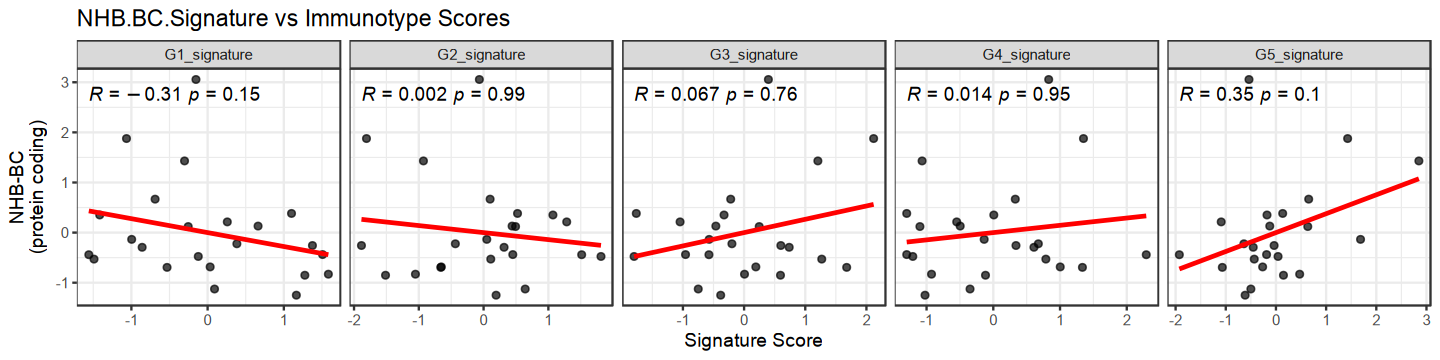

In [23]:
options(repr.plot.width=12, repr.plot.height=3)

library(ggplot2)
library(ggpubr)

score_names = c('G1_signature','G2_signature','G3_signature','G4_signature','G5_signature'
             )


# Make long-format data for easier plotting
library(tidyr)
df_long <- mat_scaled %>% data.frame() %>%
  pivot_longer(
    cols = all_of(score_names),
    names_to = "Signature",
    values_to = "Score"
  )

# Plot using ggplot2 + ggpubr (one panel per signature)
p <- ggplot(df_long, aes(x = Score, y = NHB.BC.Delta.All)) +
  geom_point(alpha = 0.7) +
  geom_smooth(method = "lm", se = FALSE, color = "red") +
  stat_cor(aes(label = paste(..r.label.., ..p.label.., sep = "~")), method = "spearman") +
  facet_wrap(~ Signature, scales = "free_x", ncol=5) +
  theme_bw() +
  labs(title = "NHB.BC.Signature vs Immunotype Scores", y = "NHB-BC\n(protein coding)", x = "Signature Score")

print(p)

`geom_smooth()` using formula = 'y ~ x'


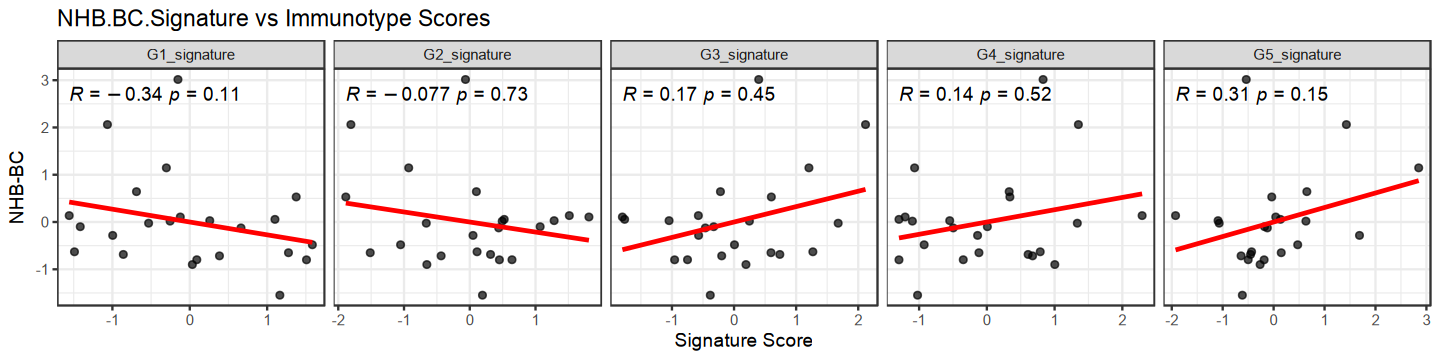

In [24]:
options(repr.plot.width=12, repr.plot.height=3)

library(ggplot2)
library(ggpubr)

score_names = c('G1_signature','G2_signature','G3_signature','G4_signature','G5_signature'
             )


# Make long-format data for easier plotting
library(tidyr)
df_long <- mat_scaled %>% data.frame() %>%
  pivot_longer(
    cols = all_of(score_names),
    names_to = "Signature",
    values_to = "Score"
  )

# Plot using ggplot2 + ggpubr (one panel per signature)
p <- ggplot(df_long, aes(x = Score, y = NHB.BC.Delta.Protein)) +
  geom_point(alpha = 0.7) +
  geom_smooth(method = "lm", se = FALSE, color = "red") +
  stat_cor(aes(label = paste(..r.label.., ..p.label.., sep = "~")), method = "spearman") +
  facet_wrap(~ Signature, scales = "free_x", ncol=5) +
  theme_bw() +
  labs(title = "NHB.BC.Signature vs Immunotype Scores", y = "NHB-BC", x = "Signature Score")

print(p)